In [5]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from google.colab import drive

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

#drive.mount("/content/drive")

In [6]:
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

PROJECT_DIR = Path("/content/drive/MyDrive/Assigment")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/Assigment


In [7]:
filename_options = {
    "development": ["train-test.csv"],
    "inference": ["validation.csv"],
    "template": [
        "validation-predictions-template.csv"
    ],
    "december": [
        "december-chart-inputs.csv"
    ],
}

dataframes = {}

for dataset_name, options in filename_options.items():
    matches = [
        DATA_DIR / filename
        for filename in options
        if (DATA_DIR / filename).is_file()
    ]

    saved_path = matches[0]

    # Read the complete CSV
    dataframes[dataset_name] = pd.read_csv(saved_path)

    print(
        f"{dataset_name}: "
        f"{dataframes[dataset_name].shape[0]:,} rows, "
        f"{dataframes[dataset_name].shape[1]} columns "
        f"({saved_path.name})"
    )

train_raw = dataframes["development"]
inference_raw = dataframes["inference"]
template_raw = dataframes["template"]
december_raw = dataframes["december"]

development: 48,000 rows, 14 columns (train-test.csv)
inference: 12,000 rows, 13 columns (validation.csv)
template: 12,000 rows, 2 columns (validation-predictions-template.csv)
december: 31 rows, 7 columns (december-chart-inputs.csv)


In [15]:
FEATURE_COLUMNS = [
    "pickup",
    "delivery",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "equipment",
    "weight",
    "date",
    "market_index",
    "quote_signal",
]

TARGET = "posted_rate"

expected_columns = {
    "development": ["load_id"] + FEATURE_COLUMNS + [TARGET],
    "inference": ["load_id"] + FEATURE_COLUMNS,
    "template": ["load_id", "predicted_rate"],
    "december": [
        "pickup",
        "delivery",
        "distance",
        "equipment",
        "weight",
        "date",
        "predicted_rate",
    ],
}

expected_rows = {
    "development": 48_000,
    "inference": 12_000,
    "template": 12_000,
    "december": 31,
}

# 1. Check every dataset's columns and row count.
for name, frame in dataframes.items():
    assert list(frame.columns) == expected_columns[name], (
        f"Unexpected columns in {name}: {list(frame.columns)}"
    )

    assert len(frame) == expected_rows[name], (
        f"Unexpected row count in {name}: {len(frame):,}"
    )

# 2. Check IDs in the three files that contain them.
for name in ["development", "inference", "template"]:
    ids = dataframes[name]["load_id"]

    assert ids.notna().all(), f"Missing IDs in {name}"
    assert ids.is_unique, f"Duplicate IDs in {name}"

assert set(template_raw["load_id"]) == set(inference_raw["load_id"]), (
    "Template IDs do not match inference IDs."
)

assert set(train_raw["load_id"]).isdisjoint(
    set(inference_raw["load_id"])
), "Development and inference IDs overlap."

expected_final_ids = {
    f"TE-{number:06d}" for number in range(1, 12_001)
}

assert set(inference_raw["load_id"]) == expected_final_ids, (
    "Final IDs do not match the scorer's required IDs."
)

# 3. Check that labels exist only where expected.
assert train_raw[TARGET].notna().all(), "Missing development targets."
assert TARGET not in inference_raw.columns

# 4. Parse dates into temporary variables; leave raw frames unchanged.
train_dates = pd.to_datetime(
    train_raw["date"], format="%Y-%m-%d", errors="raise"
)
inference_dates = pd.to_datetime(
    inference_raw["date"], format="%Y-%m-%d", errors="raise"
)

assert train_dates.notna().all()
assert inference_dates.notna().all()
assert train_dates.max() < inference_dates.min(), (
    "Expected final inference dates to follow development dates."
)

print("Schema, row-count, ID, target, and date checks passed.")

print("\nDate coverage:")
display(pd.DataFrame({
    "dataset": ["development", "final inference"],
    "rows": [len(train_raw), len(inference_raw)],
    "first_date": [
        train_dates.min().date(),
        inference_dates.min().date(),
    ],
    "last_date": [
        train_dates.max().date(),
        inference_dates.max().date(),
    ],
}))



Schema, row-count, ID, target, and date checks passed.

Date coverage:


,dataset,rows,first_date,last_date
0,development,48000,2025-01-01,2025-10-31
1,final inference,12000,2025-11-01,2025-12-31


In [14]:
print("\nDevelopment preview — only the display is limited to five rows:")
display(train_raw.head())

print("\nColumn types and missing values — calculated over ALL rows:")
display(pd.DataFrame({
    "development_dtype": train_raw.dtypes.astype(str),
    "development_missing": train_raw.isna().sum(),
    "development_missing_pct": (
        train_raw.isna().mean().mul(100).round(3)
    ),
}))

print("\nFinal inference missing values — calculated over ALL rows:")
display(
    inference_raw.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)


Development preview — only the display is limited to five rows:


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28



Column types and missing values — calculated over ALL rows:


,development_dtype,development_missing,development_missing_pct
load_id,object,0,0.000
pickup,object,0,0.000
delivery,object,0,0.000
pickup_lat,float64,0,0.000
pickup_lon,float64,0,0.000
delivery_lat,float64,0,0.000
delivery_lon,float64,0,0.000
distance,float64,0,0.000
equipment,object,0,0.000
weight,float64,300,0.625



Final inference missing values — calculated over ALL rows:


,missing_count
load_id,0
pickup,0
delivery,0
pickup_lat,0
pickup_lon,0
delivery_lat,0
delivery_lon,0
distance,0
equipment,0
weight,165


##Inspect numerical values and data-quality issues

In [16]:
import matplotlib.pyplot as plt

NUMERIC_FEATURES = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
]

# Inspect the original values before any conversion.
quality_records = []

for dataset_name, frame in [
    ("development", train_raw),
    ("final inference", inference_raw),
]:
    numeric_columns = NUMERIC_FEATURES.copy()

    if TARGET in frame.columns:
        numeric_columns.append(TARGET)

    for column in numeric_columns:
        original = frame[column]
        numeric = pd.to_numeric(original, errors="coerce")

        quality_records.append({
            "dataset": dataset_name,
            "column": column,
            "missing": int(original.isna().sum()),
            "unparseable": int(
                (original.notna() & numeric.isna()).sum()
            ),
            "infinite": int(numeric.isin([np.inf, -np.inf]).sum()),
            "negative": int(numeric.lt(0).sum()),
            "zero": int(numeric.eq(0).sum()),
        })

quality_summary = pd.DataFrame(quality_records)

print("Numerical data-quality checks:")
display(quality_summary)

# Exploration copies only: no imputation or row removal.
eda_train = train_raw.copy(deep=True)
eda_inference = inference_raw.copy(deep=True)

for frame in [eda_train, eda_inference]:
    frame["date"] = pd.to_datetime(
        frame["date"], format="%Y-%m-%d", errors="raise"
    )

    for column in NUMERIC_FEATURES:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

eda_train[TARGET] = pd.to_numeric(
    eda_train[TARGET], errors="coerce"
)

print("\nDevelopment numerical distributions:")
display(
    eda_train[
        ["distance", "weight", "market_index", "quote_signal", TARGET]
    ]
    .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])
    .T
    .round(3)
)

print("\nExamples of loads with negative weights:")
display(
    train_raw.loc[
        pd.to_numeric(train_raw["weight"], errors="coerce").lt(0),
        ["load_id", "equipment", "distance", "weight", TARGET],
    ].head(10)
)

Numerical data-quality checks:


,dataset,column,missing,unparseable,infinite,negative,zero
0,development,pickup_lat,0,0,0,0,0
1,development,pickup_lon,0,0,0,48000,0
2,development,delivery_lat,0,0,0,0,0
3,development,delivery_lon,0,0,0,48000,0
4,development,distance,0,0,0,0,0
5,development,weight,300,0,0,292,0
6,development,market_index,374,0,0,0,0
7,development,quote_signal,0,0,0,0,0
8,development,posted_rate,0,0,0,0,0
9,final inference,pickup_lat,0,0,0,0,0



Development numerical distributions:


,count,mean,std,min,1%,25%,50%,75%,99%,max
distance,48000.0,1135.857,728.564,70.000,121.899,550.400,953.300,1645.525,3029.304,3439.800
weight,47700.0,31028.844,9391.441,-47500.000,9801.960,25800.000,31436.500,37018.000,47500.000,47500.000
market_index,47626.0,1.083,0.168,0.676,0.783,0.950,1.056,1.220,1.407,1.468
quote_signal,48000.0,2.062,0.291,0.692,1.305,1.891,2.056,2.222,2.884,3.610
posted_rate,48000.0,2373.981,1486.493,57.220,327.169,1251.555,2030.760,3330.750,5972.834,25533.000



Examples of loads with negative weights:


,load_id,equipment,distance,weight,posted_rate
68,TR-000069,Reefer,1334.2,-36559.0,2831.27
204,TR-000205,Dry Van,496.2,-26670.0,1046.92
206,TR-000207,Reefer,411.3,-20003.0,959.15
225,TR-000226,Reefer,1317.4,-23981.0,2836.00
376,TR-000377,Dry Van,1331.1,-41397.0,2522.54
446,TR-000447,Reefer,2438.3,-37215.0,4841.57
495,TR-000496,Dry Van,715.9,-31214.0,1473.78
641,TR-000642,Dry Van,582.4,-41023.0,1264.33
806,TR-000807,Dry Van,676.1,-28320.0,1307.76
1093,TR-001094,Dry Van,1058.5,-25153.0,1907.83


- Negative longitude is normal; negative shipment weight is not.
- unparseable detects nonmissing text that cannot be converted to a number.
- The difference between the 99th percentile and maximum helps identify unusually large values.
- We are flagging issues, not deleting rows.
You should see 300 missing and 292 negative development weights, and 165 missing and 145 negative final-inference weights.

##Examine rates, distance, and equipment

Rate-per-mile distribution:


,rate_per_mile
count,48000.000
mean,2.215
std,0.584
min,0.334
0.1%,0.437
1%,1.674
50%,2.145
99%,3.177
99.9%,10.069
max,14.125



Summary by equipment:


,loads,median_distance,median_total_rate,median_rate_per_mile
equipment,,,,
Dry Van,27202,957.55,1953.035,2.046
Flatbed,8753,940.00,2076.810,2.220
Reefer,12045,950.20,2196.670,2.312



Summary by distance band:


,loads,median_total_rate,median_rate_per_mile
distance_band,,,
0–250,2713,506.09,2.745
250–500,7577,924.07,2.423
"500–1,000",15055,1632.28,2.195
"1,000–2,000",15108,2872.25,2.046
"2,000+",7547,4531.93,1.912


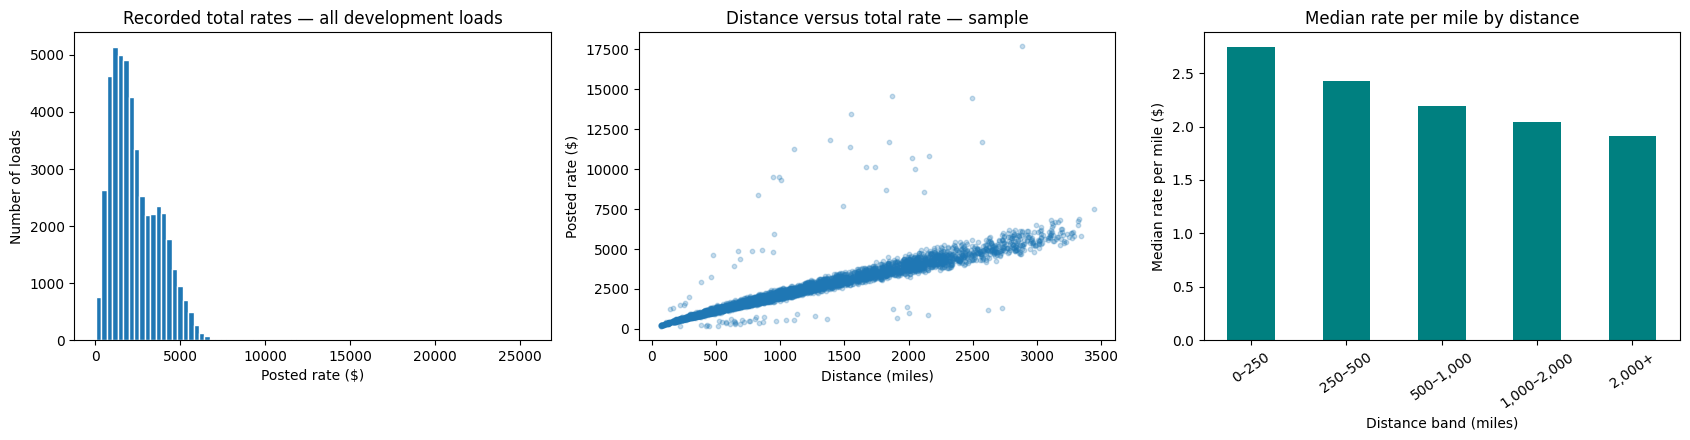

In [17]:
# Target-derived diagnostic: never add this to the predictor feature list.
eda_train["rate_per_mile"] = (
    eda_train[TARGET]
    / eda_train["distance"].where(eda_train["distance"] > 0)
)

print("Rate-per-mile distribution:")
display(
    eda_train["rate_per_mile"]
    .describe(percentiles=[0.001, 0.01, 0.50, 0.99, 0.999])
    .to_frame()
    .round(3)
)

print("\nSummary by equipment:")
equipment_summary = (
    eda_train.groupby("equipment")
    .agg(
        loads=("load_id", "size"),
        median_distance=("distance", "median"),
        median_total_rate=(TARGET, "median"),
        median_rate_per_mile=("rate_per_mile", "median"),
    )
    .round(3)
)
display(equipment_summary)

eda_train["distance_band"] = pd.cut(
    eda_train["distance"],
    bins=[0, 250, 500, 1000, 2000, np.inf],
    labels=["0–250", "250–500", "500–1,000", "1,000–2,000", "2,000+"],
    include_lowest=True,
)

print("\nSummary by distance band:")
distance_summary = (
    eda_train.groupby("distance_band", observed=True)
    .agg(
        loads=("load_id", "size"),
        median_total_rate=(TARGET, "median"),
        median_rate_per_mile=("rate_per_mile", "median"),
    )
    .round(3)
)
display(distance_summary)

# Sample only for scatter-plot readability.
# All summary tables above use every development row.
plot_sample = eda_train.sample(
    n=min(5000, len(eda_train)),
    random_state=SEED,
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(eda_train[TARGET], bins=80, edgecolor="white")
axes[0].set_title("Recorded total rates — all development loads")
axes[0].set_xlabel("Posted rate ($)")
axes[0].set_ylabel("Number of loads")

axes[1].scatter(
    plot_sample["distance"],
    plot_sample[TARGET],
    s=10,
    alpha=0.25,
)
axes[1].set_title("Distance versus total rate — sample")
axes[1].set_xlabel("Distance (miles)")
axes[1].set_ylabel("Posted rate ($)")

distance_summary["median_rate_per_mile"].plot.bar(
    ax=axes[2], color="teal"
)
axes[2].set_title("Median rate per mile by distance")
axes[2].set_xlabel("Distance band (miles)")
axes[2].set_ylabel("Median rate per mile ($)")
axes[2].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Patterns:
- Total rates generally increase with distance.
- Rate per mile generally decreases as shipment distance increases.
- Equipment groups have different pricing distributions.
- A few large rates stretch the distribution.

##Check unfamiliar cities and lanes

In [18]:
known_cities = (
    set(train_raw["pickup"])
    | set(train_raw["delivery"])
)

final_cities = (
    set(inference_raw["pickup"])
    | set(inference_raw["delivery"])
)

new_cities = sorted(final_cities - known_cities)

known_lanes = set(
    zip(train_raw["pickup"], train_raw["delivery"])
)

final_lanes = list(
    zip(inference_raw["pickup"], inference_raw["delivery"])
)

new_city_mask = (
    ~inference_raw["pickup"].isin(known_cities)
    | ~inference_raw["delivery"].isin(known_cities)
)

new_lane_mask = pd.Series(
    [lane not in known_lanes for lane in final_lanes],
    index=inference_raw.index,
)

coverage_summary = pd.DataFrame({
    "condition": [
        "At least one previously unseen city",
        "Previously unseen directional lane",
        "Unseen lane between previously seen cities",
    ],
    "loads": [
        int(new_city_mask.sum()),
        int(new_lane_mask.sum()),
        int((new_lane_mask & ~new_city_mask).sum()),
    ],
})

coverage_summary["percent_of_final_loads"] = (
    coverage_summary["loads"] / len(inference_raw) * 100
).round(2)

print("Cities present only in final inference:")
print(new_cities)

print("\nFinal inference coverage:")
display(coverage_summary)

print("\nExamples involving a previously unseen city:")
display(
    inference_raw.loc[
        new_city_mask,
        [
            "load_id", "pickup", "delivery",
            "distance", "equipment", "date",
        ],
    ].head(10)
)

Cities present only in final inference:
['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']

Final inference coverage:


,condition,loads,percent_of_final_loads
0,At least one previously unseen city,1447,12.06
1,Previously unseen directional lane,1461,12.18
2,Unseen lane between previously seen cities,14,0.12



Examples involving a previously unseen city:


,load_id,pickup,delivery,distance,equipment,date
9,TE-000010,Norfolk,Columbia,534.4,Dry Van,2025-11-01
18,TE-000019,Atlanta,Jackson,404.0,Dry Van,2025-11-01
20,TE-000021,Phoenix,Charlotte,2376.3,Reefer,2025-11-01
49,TE-000050,Allentown,Phoenix,2766.4,Dry Van,2025-11-01
65,TE-000066,Allentown,Milwaukee,904.1,Flatbed,2025-11-01
69,TE-000070,Tucson,Jackson,1478.3,Dry Van,2025-11-01
84,TE-000085,Knoxville,Charleston,462.5,Dry Van,2025-11-01
85,TE-000086,Lubbock,Allentown,1901.9,Reefer,2025-11-01
86,TE-000087,Laredo,Albany,2260.0,Reefer,2025-11-01
100,TE-000101,Jackson,Memphis,320.5,Flatbed,2025-11-01


Tells us why the eventual model needs to handle unseen categories and why coordinates may be useful.

##Investigate time patterns and the quote signal

Monthly development diagnostics:


,month,loads,median_total_rate,median_rate_per_mile,mean_market_index,quote_rpm_correlation,weight_missing_pct,weight_negative_pct
0,2025-01,4918,1915.200,2.0292,0.9267,0.4467,0.6913,0.6303
1,2025-02,4337,1994.250,2.0611,0.9960,0.4790,0.7609,0.6917
2,2025-03,5036,2022.920,2.1393,1.0729,0.4858,0.7149,0.7943
3,2025-04,4819,2044.240,2.1467,1.2076,-0.4717,0.4150,0.5188
4,2025-05,4913,2065.510,2.1902,1.3015,-0.4592,0.4478,0.8142
5,2025-06,4783,2120.220,2.2479,1.2803,0.4766,0.6690,0.6272
6,2025-07,4912,2059.145,2.1874,1.2009,-0.4683,0.5904,0.4479
7,2025-08,4759,2015.730,2.1205,0.9815,-0.0136,0.6094,0.3152
8,2025-09,4670,2057.130,2.1596,0.8930,0.4814,0.7066,0.5567
9,2025-10,4853,2035.900,2.1638,0.9575,-0.4340,0.6594,0.6800


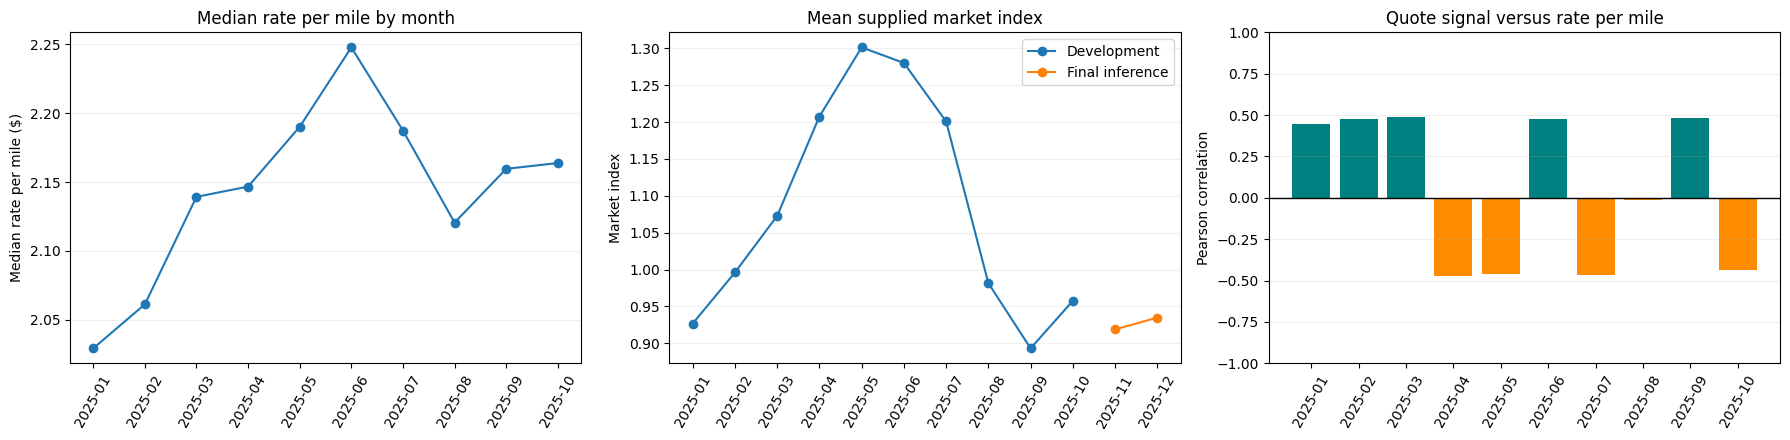

EDA tables saved to: /content/drive/MyDrive/Assigment/outputs
Original dataframes remain unchanged.


In [19]:
monthly_records = []

for month, group in eda_train.groupby(
    eda_train["date"].dt.to_period("M"),
    sort=True,
):
    monthly_records.append({
        "month": str(month),
        "loads": len(group),
        "median_total_rate": group[TARGET].median(),
        "median_rate_per_mile": group["rate_per_mile"].median(),
        "mean_market_index": group["market_index"].mean(),
        "quote_rpm_correlation": (
            group["quote_signal"].corr(group["rate_per_mile"])
        ),
        "weight_missing_pct": group["weight"].isna().mean() * 100,
        "weight_negative_pct": group["weight"].lt(0).mean() * 100,
    })

monthly_summary = pd.DataFrame(monthly_records)

print("Monthly development diagnostics:")
display(monthly_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(
    monthly_summary["month"],
    monthly_summary["median_rate_per_mile"],
    marker="o",
)
axes[0].set_title("Median rate per mile by month")
axes[0].set_ylabel("Median rate per mile ($)")

# Include final features for distribution inspection only.
# No final labels are available or used.
for label, frame in [
    ("Development", eda_train),
    ("Final inference", eda_inference),
]:
    monthly_market = (
        frame.groupby(frame["date"].dt.to_period("M"))["market_index"]
        .mean()
    )

    axes[1].plot(
        monthly_market.index.astype(str),
        monthly_market.values,
        marker="o",
        label=label,
    )

axes[1].set_title("Mean supplied market index")
axes[1].set_ylabel("Market index")
axes[1].legend()

correlations = monthly_summary["quote_rpm_correlation"]
colors = np.where(correlations >= 0, "teal", "darkorange")

axes[2].bar(
    monthly_summary["month"],
    correlations,
    color=colors,
)
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_ylim(-1, 1)
axes[2].set_title("Quote signal versus rate per mile")
axes[2].set_ylabel("Pearson correlation")

for axis in axes:
    axis.tick_params(axis="x", rotation=60)
    axis.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Save the small diagnostic tables for later reporting.
quality_summary.to_csv(
    OUTPUT_DIR / "eda_numeric_quality.csv", index=False
)
equipment_summary.to_csv(
    OUTPUT_DIR / "eda_equipment_summary.csv"
)
distance_summary.to_csv(
    OUTPUT_DIR / "eda_distance_summary.csv"
)
coverage_summary.to_csv(
    OUTPUT_DIR / "eda_final_coverage.csv", index=False
)
monthly_summary.to_csv(
    OUTPUT_DIR / "eda_monthly_summary.csv", index=False
)

print("EDA tables saved to:", OUTPUT_DIR)
print("Original dataframes remain unchanged.")

Result is the changing sign of the quote correlation. This supports testing the model without that feature rather than assuming it is consistently useful. Monthly changes in median rates may also reflect changing shipment mixes, so they are not automatically pure market effects

## Prepare clean working copies and define the chronological splits. These will be reused by the baselines and CatBoost so their results are comparable.
We’ll make three decisions now:
- Treat nonpositive weights as invalid and replace them with missing values.
- Preserve indicators distinguishing originally missing weights from invalid weights.
- Keep missing numerical values unfilled until we fit a model. Any learned imputation must use that model’s training partition only.

In [20]:
def clean_load_data(raw):
    """
    Apply deterministic cleaning rules to a fresh copy.

    No fitted statistics, target encoding, imputation, or row removal.
    Intended for the main development and final-inference datasets.
    """
    required = {"load_id", *FEATURE_COLUMNS}
    missing_columns = required - set(raw.columns)

    if missing_columns:
        raise ValueError(
            f"Required columns are missing: {sorted(missing_columns)}"
        )

    # Explicitly select source columns.
    # This prevents target-derived EDA columns from entering this dataset.
    source_columns = ["load_id"] + FEATURE_COLUMNS

    if TARGET in raw.columns:
        source_columns.append(TARGET)

    cleaned = raw.loc[:, source_columns].copy(deep=True)

    # Parse dates strictly.
    cleaned["date"] = pd.to_datetime(
        cleaned["date"],
        format="%Y-%m-%d",
        errors="raise",
    )

    if cleaned["date"].isna().any():
        raise ValueError("Missing load dates.")

    # Normalize categorical strings.
    for column in ["pickup", "delivery", "equipment"]:
        cleaned[column] = (
            cleaned[column]
            .astype("string")
            .str.strip()
            .fillna("__MISSING__")
            .replace("", "__MISSING__")
            .astype(str)
        )

    # Parse numerical inputs.
    # Unexpected nonnumeric strings should raise an error, not disappear.
    for column in NUMERIC_FEATURES:
        cleaned[column] = pd.to_numeric(
            cleaned[column], errors="raise"
        ).astype(float)

        if cleaned[column].isin([np.inf, -np.inf]).any():
            raise ValueError(f"Infinite values found in {column}.")

    # Distance is required for our mileage baseline.
    if (
        cleaned["distance"].isna().any()
        or cleaned["distance"].le(0).any()
    ):
        raise ValueError("Distance must be present and positive.")

    # Keep the reason for a missing weight.
    cleaned["weight_was_missing"] = (
        cleaned["weight"].isna().astype("int8")
    )

    cleaned["weight_was_invalid"] = (
        cleaned["weight"].le(0).astype("int8")
    )

    cleaned.loc[
        cleaned["weight_was_invalid"].eq(1), "weight"
    ] = np.nan

    # Preserve missing market information for later modeling.
    cleaned["market_index_was_missing"] = (
        cleaned["market_index"].isna().astype("int8")
    )

    # Validate labels without modifying their values.
    if TARGET in cleaned.columns:
        cleaned[TARGET] = pd.to_numeric(
            cleaned[TARGET], errors="raise"
        )

        if (
            cleaned[TARGET].isna().any()
            or not np.isfinite(cleaned[TARGET]).all()
            or cleaned[TARGET].le(0).any()
        ):
            raise ValueError("Targets must be finite and positive.")

    return cleaned


train_df = clean_load_data(train_raw)
inference_df = clean_load_data(inference_raw)

cleaning_summary = pd.DataFrame([
    {
        "dataset": name,
        "rows": len(frame),
        "originally_missing_weight": int(
            frame["weight_was_missing"].sum()
        ),
        "invalid_weight": int(
            frame["weight_was_invalid"].sum()
        ),
        "weight_missing_after_cleaning": int(
            frame["weight"].isna().sum()
        ),
        "missing_market_index": int(
            frame["market_index_was_missing"].sum()
        ),
    }
    for name, frame in [
        ("development", train_df),
        ("final inference", inference_df),
    ]
])

display(cleaning_summary)

,dataset,rows,originally_missing_weight,invalid_weight,weight_missing_after_cleaning,missing_market_index
0,development,48000,300,292,592,374
1,final inference,12000,165,145,310,249


Why not fill these with a global median now? Because that would let an earlier training period use information from later evaluation rows. We’ll fit any imputer inside each training partition. Our initial mileage baseline won’t need weight at all.

##Define the temporal folds

In [21]:
FOLD_SPECS = [
    {
        "name": "fold_A",
        "purpose": "development",
        "train_end": "2025-02-28",
        "eval_start": "2025-03-01",
        "eval_end": "2025-04-30",
    },
    {
        "name": "fold_B",
        "purpose": "development",
        "train_end": "2025-04-30",
        "eval_start": "2025-05-01",
        "eval_end": "2025-06-30",
    },
    {
        "name": "fold_C",
        "purpose": "development",
        "train_end": "2025-06-30",
        "eval_start": "2025-07-01",
        "eval_end": "2025-08-31",
    },
    {
        "name": "reserved",
        "purpose": "reserved_model_comparison",
        "train_end": "2025-08-31",
        "eval_start": "2025-09-01",
        "eval_end": "2025-10-31",
    },
]

folds = {}
fold_records = []

assert train_df.index.is_unique

for spec in FOLD_SPECS:
    train_end = pd.Timestamp(spec["train_end"])
    eval_start = pd.Timestamp(spec["eval_start"])
    eval_end = pd.Timestamp(spec["eval_end"])

    train_mask = train_df["date"].le(train_end)
    eval_mask = train_df["date"].between(
        eval_start, eval_end, inclusive="both"
    )

    train_idx = train_df.index[train_mask]
    eval_idx = train_df.index[eval_mask]

    assert len(train_idx) > 0
    assert len(eval_idx) > 0
    assert train_idx.intersection(eval_idx).empty

    fit_dates = train_df.loc[train_idx, "date"]
    evaluation_dates = train_df.loc[eval_idx, "date"]

    # Every fitting observation precedes every evaluation observation.
    assert fit_dates.max() < evaluation_dates.min()

    # No calendar date appears on both sides of this fold.
    assert set(fit_dates).isdisjoint(set(evaluation_dates))

    folds[spec["name"]] = {
        **spec,
        "train_idx": train_idx,
        "eval_idx": eval_idx,
    }

    fold_records.append({
        "fold": spec["name"],
        "purpose": spec["purpose"],
        "train_start": fit_dates.min().date(),
        "train_end": fit_dates.max().date(),
        "eval_start": evaluation_dates.min().date(),
        "eval_end": evaluation_dates.max().date(),
        "train_rows": len(train_idx),
        "eval_rows": len(eval_idx),
    })

fold_summary = pd.DataFrame(fold_records)

display(fold_summary)

# Use these three folds for feature and parameter decisions.
DEVELOPMENT_FOLDS = ["fold_A", "fold_B", "fold_C"]

# Keep this separate from routine tuning.
RESERVED_FOLD = "reserved"

,fold,purpose,train_start,train_end,eval_start,eval_end,train_rows,eval_rows
0,fold_A,development,2025-01-01,2025-02-28,2025-03-01,2025-04-30,9255,9855
1,fold_B,development,2025-01-01,2025-04-30,2025-05-01,2025-06-30,19110,9696
2,fold_C,development,2025-01-01,2025-06-30,2025-07-01,2025-08-31,28806,9671
3,reserved,reserved_model_comparison,2025-01-01,2025-08-31,2025-09-01,2025-10-31,38477,9523


The training windows intentionally overlap and expand. A load evaluated in an earlier fold can become historical training data in a later fold—that matches how a model could be retrained over time.
September–October has already appeared in our exploratory analysis, so we will describe it as a reserved model-comparison period, not a completely untouched test set.

##Verify preservation and save the split definitions

This checks that cleaning did not remove shipments or change their answers. It also saves the fold membership by ID so we can reproduce the evaluation later.

In [22]:
# 1. Preserve all original rows and their order.
assert len(train_df) == len(train_raw)
assert len(inference_df) == len(inference_raw)

assert train_df["load_id"].equals(train_raw["load_id"])
assert inference_df["load_id"].equals(inference_raw["load_id"])

# 2. Preserve every development label exactly.
np.testing.assert_array_equal(
    train_df[TARGET].to_numpy(),
    pd.to_numeric(train_raw[TARGET], errors="raise").to_numpy(),
)

# 3. Confirm that invalid weights were handled.
assert not train_df["weight"].dropna().le(0).any()
assert not inference_df["weight"].dropna().le(0).any()

# 4. Confirm EDA-only target-derived columns are absent.
assert "rate_per_mile" not in train_df.columns
assert "rate_per_mile" not in inference_df.columns
assert TARGET not in inference_df.columns

# 5. Preserve the separation from the final prediction period.
assert train_df["date"].max() < inference_df["date"].min()

# 6. Save exact fold membership.
membership_parts = []

for fold_name, fold in folds.items():
    for partition, index_key in [
        ("train", "train_idx"),
        ("evaluation", "eval_idx"),
    ]:
        part = train_df.loc[
            fold[index_key], ["load_id", "date"]
        ].copy()

        part.insert(0, "partition", partition)
        part.insert(0, "fold", fold_name)
        membership_parts.append(part)

split_membership = pd.concat(
    membership_parts, ignore_index=True
)

cleaning_summary.to_csv(
    OUTPUT_DIR / "cleaning_summary.csv", index=False
)

fold_summary.to_csv(
    OUTPUT_DIR / "fold_summary.csv", index=False
)

split_membership.to_csv(
    OUTPUT_DIR / "split_membership.csv", index=False
)

print("All cleaning and split checks passed.")
print("No rows removed. No targets changed. No imputation fitted.")
print("Split definitions saved to:", OUTPUT_DIR)

# Example: retrieve the first fold's two partitions.
fold_A_train = train_df.loc[folds["fold_A"]["train_idx"]]
fold_A_eval = train_df.loc[folds["fold_A"]["eval_idx"]]

print(
    f"\nFold A ready: {len(fold_A_train):,} training rows, "
    f"{len(fold_A_eval):,} evaluation rows."
)

All cleaning and split checks passed.
No rows removed. No targets changed. No imputation fitted.
Split definitions saved to: /content/drive/MyDrive/Assigment/outputs

Fold A ready: 9,255 training rows, 9,855 evaluation rows.


##A baseline gives us a reference point: CatBoost should deliver a meaningful improvement over these simpler methods.
We’ll compare:
1. Constant median: predict the median total rate from the training partition for every evaluation load.
2. Equipment-mileage: multiply each load’s distance by the training partition’s median rate per mile for its equipment type.
We’ll use development folds A–C only. September–October stays outside this tuning loop.

In [23]:
def regression_metrics(actual, predicted):
    """Calculate metrics on total shipment rates in dollars."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if actual.ndim != 1 or actual.shape != predicted.shape:
        raise ValueError("Actual and predicted must be matching 1D arrays.")

    if len(actual) == 0:
        raise ValueError("Cannot evaluate empty predictions.")

    if not np.isfinite(actual).all():
        raise ValueError("Actual rates contain missing or infinite values.")

    if not np.isfinite(predicted).all():
        raise ValueError("Predictions contain missing or infinite values.")

    if (actual <= 0).any():
        raise ValueError("Expected positive actual shipment rates.")

    error = predicted - actual

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": (
            100 * np.sum(np.abs(error)) / np.sum(np.abs(actual))
        ),
        "bias": np.mean(error),
    }


def fit_baselines(fitting_data):
    """Learn baseline parameters using only the fitting partition."""
    rate_per_mile = (
        fitting_data[TARGET] / fitting_data["distance"]
    )

    equipment_medians = (
        pd.DataFrame({
            "equipment": fitting_data["equipment"],
            "rate_per_mile": rate_per_mile,
        })
        .groupby("equipment")["rate_per_mile"]
        .median()
        .to_dict()
    )

    return {
        "median_total_rate": float(fitting_data[TARGET].median()),
        "global_median_rpm": float(rate_per_mile.median()),
        "equipment_median_rpm": equipment_medians,
    }


def predict_baselines(parameters, features):
    """
    Predict from features only.

    If an equipment category was absent during fitting,
    use the training partition's global median rate per mile.
    """
    equipment_rpm = (
        features["equipment"]
        .map(parameters["equipment_median_rpm"])
        .fillna(parameters["global_median_rpm"])
    )

    predictions = {
        "constant_median": np.full(
            len(features),
            parameters["median_total_rate"],
            dtype=float,
        ),
        "equipment_mileage": (
            features["distance"] * equipment_rpm
        ).to_numpy(dtype=float),
    }

    for name, values in predictions.items():
        if not np.isfinite(values).all() or (values <= 0).any():
            raise ValueError(f"Invalid predictions from {name}.")

    return predictions


print("Metric and baseline functions are ready.")

Metric and baseline functions are ready.


Metric	Meaning

MAE:	Average absolute dollar error; lower is better

RMSE:	Dollar error measure that emphasizes large mistakes; lower is better

WAPE:	Total absolute error as a percentage of total actual rates

Bias:	Average predicted minus actual rate; positive means overprediction

##Fit and evaluate each temporal fold
Each fold gets independently fitted baseline parameters. Evaluation labels are used only to calculate metrics.

In [24]:
baseline_metric_records = []
baseline_prediction_parts = []
baseline_parameters = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]

    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]].copy()
    evaluation_data = train_df.loc[fold["eval_idx"]].copy()

    # Fit using earlier labeled data only.
    parameters = fit_baselines(fitting_data)
    baseline_parameters[fold_name] = parameters

    # Pass only the inputs required for prediction.
    evaluation_features = evaluation_data[
        ["distance", "equipment"]
    ]

    predictions_by_model = predict_baselines(
        parameters, evaluation_features
    )

    for model_name, predicted in predictions_by_model.items():
        metrics = regression_metrics(
            evaluation_data[TARGET], predicted
        )

        baseline_metric_records.append({
            "fold": fold_name,
            "model": model_name,
            "train_rows": len(fitting_data),
            "eval_rows": len(evaluation_data),
            **metrics,
        })

        # Keep individual errors for later comparisons and diagnostics.
        prediction_frame = evaluation_data[
            ["load_id", "date", "equipment", "distance", TARGET]
        ].copy()

        prediction_frame = prediction_frame.rename(
            columns={TARGET: "actual_rate"}
        )

        prediction_frame["fold"] = fold_name
        prediction_frame["model"] = model_name
        prediction_frame["predicted_rate"] = predicted

        prediction_frame["error"] = (
            prediction_frame["predicted_rate"]
            - prediction_frame["actual_rate"]
        )

        prediction_frame["absolute_error"] = (
            prediction_frame["error"].abs()
        )

        baseline_prediction_parts.append(prediction_frame)

baseline_results = pd.DataFrame(baseline_metric_records)

baseline_oof = pd.concat(
    baseline_prediction_parts,
    ignore_index=True,
)

# Evaluation periods are disjoint, so each model should predict
# each evaluated load exactly once.
assert not baseline_oof.duplicated(
    subset=["model", "load_id"]
).any()

assert set(baseline_results["fold"]) == set(DEVELOPMENT_FOLDS)

print("Results for each temporal fold:")
display(
    baseline_results.sort_values(["fold", "model"]).round(2)
)

print("\nMAE comparison:")
display(
    baseline_results.pivot(
        index="fold",
        columns="model",
        values="MAE",
    ).round(2)
)

Results for each temporal fold:


,fold,model,train_rows,eval_rows,MAE,RMSE,WAPE_pct,bias
0,fold_A,constant_median,9255,9855,1126.74,1521.90,47.50,-420.47
1,fold_A,equipment_mileage,9255,9855,191.06,558.83,8.05,-48.80
2,fold_B,constant_median,19110,9696,1175.96,1616.17,47.82,-467.58
3,fold_B,equipment_mileage,19110,9696,206.18,654.18,8.39,-90.08
4,fold_C,constant_median,28806,9671,1128.11,1532.19,47.45,-354.50
5,fold_C,equipment_mileage,28806,9671,222.73,662.87,9.37,40.76



MAE comparison:


model,constant_median,equipment_mileage
fold,,
fold_A,1126.74,191.06
fold_B,1175.96,206.18
fold_C,1128.11,222.73


##Summarize, visualize, and save results
We’ll calculate pooled metrics directly from all out-of-fold predictions. This is particularly important for RMSE: simply averaging fold RMSEs is not the same calculation.

Pooled performance across development folds A–C:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
1,equipment_mileage,29222,206.56,626.69,8.60,-32.86
0,constant_median,29222,1143.53,1557.16,47.59,-414.27



Reduction in MAE relative to the constant baseline:


model,constant_median,equipment_mileage,equipment_mileage_MAE_reduction_pct
fold,,,
fold_A,1126.74,191.06,83.04
fold_B,1175.96,206.18,82.47
fold_C,1128.11,222.73,80.26


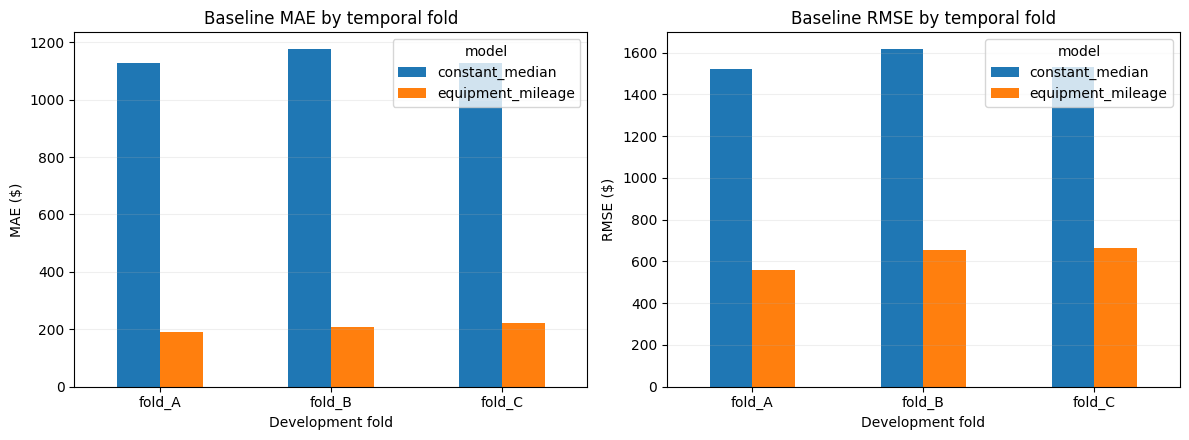

Baseline results and predictions saved to: /content/drive/MyDrive/Assigment/outputs
Reserved September–October period was not evaluated in this run.


In [25]:
pooled_records = []

for model_name, predictions in baseline_oof.groupby("model"):
    pooled_records.append({
        "model": model_name,
        "evaluated_loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

baseline_pooled = pd.DataFrame(pooled_records)

print("Pooled performance across development folds A–C:")
display(
    baseline_pooled.sort_values("MAE").round(2)
)

# Compare the two baselines within each fold.
mae_comparison = baseline_results.pivot(
    index="fold",
    columns="model",
    values="MAE",
)

mae_comparison["equipment_mileage_MAE_reduction_pct"] = (
    100
    * (
        1
        - mae_comparison["equipment_mileage"]
        / mae_comparison["constant_median"]
    )
)

print("\nReduction in MAE relative to the constant baseline:")
display(mae_comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for axis, metric in zip(axes, ["MAE", "RMSE"]):
    baseline_results.pivot(
        index="fold",
        columns="model",
        values=metric,
    ).plot.bar(ax=axis, rot=0)

    axis.set_title(f"Baseline {metric} by temporal fold")
    axis.set_ylabel(f"{metric} ($)")
    axis.set_xlabel("Development fold")
    axis.grid(axis="y", alpha=0.2)

plt.tight_layout()

figure_path = OUTPUT_DIR / "baseline_comparison.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

baseline_results.to_csv(
    OUTPUT_DIR / "baseline_fold_metrics.csv",
    index=False,
)

baseline_pooled.to_csv(
    OUTPUT_DIR / "baseline_pooled_metrics.csv",
    index=False,
)

baseline_oof.to_csv(
    OUTPUT_DIR / "baseline_oof_predictions.csv",
    index=False,
)

print("Baseline results and predictions saved to:", OUTPUT_DIR)
print("Reserved September–October period was not evaluated in this run.")

The constant baseline measures how well we can do without using shipment characteristics. The equipment-mileage baseline measures the value of distance and equipment using a simple pricing rule.
If your results match, the evaluation pipeline is reproducing our earlier findings. The stronger baseline becomes a concrete benchmark for more complex models.

##Break down errors by shipment characteristics

In [27]:
# Keep the stronger baseline's out-of-fold predictions.
baseline_diagnostics = baseline_oof.loc[
    baseline_oof["model"].eq("equipment_mileage")
].copy()

# Attach additional information for analysis only.
# These columns were not used to fit this baseline.
diagnostic_metadata = train_df[
    [
        "load_id",
        "pickup",
        "delivery",
        "weight_was_missing",
        "weight_was_invalid",
        "market_index_was_missing",
    ]
]

baseline_diagnostics = baseline_diagnostics.merge(
    diagnostic_metadata,
    on="load_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert baseline_diagnostics["_merge"].eq("both").all()
baseline_diagnostics = baseline_diagnostics.drop(columns="_merge")

baseline_diagnostics["month"] = (
    pd.to_datetime(baseline_diagnostics["date"])
    .dt.to_period("M")
    .astype(str)
)

baseline_diagnostics["distance_band"] = pd.cut(
    baseline_diagnostics["distance"],
    bins=[0, 250, 500, 1000, 2000, np.inf],
    labels=[
        "0–250",
        "250–500",
        "500–1,000",
        "1,000–2,000",
        "2,000+",
    ],
    include_lowest=True,
)

baseline_diagnostics["weight_status"] = np.select(
    [
        baseline_diagnostics["weight_was_invalid"].eq(1),
        baseline_diagnostics["weight_was_missing"].eq(1),
    ],
    ["invalid", "missing"],
    default="valid",
)


def summarize_errors_by(frame, group_column):
    """Evaluate each slice using all its original evaluation rows."""
    records = []

    for group_name, group in frame.groupby(
        group_column, observed=True, sort=True
    ):
        records.append({
            group_column: group_name,
            "loads": len(group),
            "mean_actual_rate": group["actual_rate"].mean(),
            **regression_metrics(
                group["actual_rate"],
                group["predicted_rate"],
            ),
        })

    return pd.DataFrame(records)


error_summaries = {}

for column in [
    "distance_band",
    "equipment",
    "month",
    "weight_status",
]:
    summary = summarize_errors_by(
        baseline_diagnostics, column
    )

    error_summaries[column] = summary

    print(f"\nErrors grouped by: {column}")
    display(summary.round(2))

    summary.to_csv(
        OUTPUT_DIR / f"baseline_errors_by_{column}.csv",
        index=False,
    )


Errors grouped by: distance_band


,distance_band,loads,mean_actual_rate,MAE,RMSE,WAPE_pct,bias
0,0–250,1668,495.06,131.02,180.69,26.47,-127.59
1,250–500,4585,943.22,156.21,258.90,16.56,-149.15
2,"500–1,000",9163,1682.83,151.88,410.65,9.03,-124.38
3,"1,000–2,000",9258,3029.83,190.05,728.37,6.27,-30.83
4,"2,000+",4548,4747.39,428.78,1012.01,9.03,299.40



Errors grouped by: equipment


,equipment,loads,mean_actual_rate,MAE,RMSE,WAPE_pct,bias
0,Dry Van,16561,2305.48,197.15,624.55,8.55,-29.91
1,Flatbed,5310,2478.35,215.36,602.00,8.69,-44.60
2,Reefer,7351,2567.03,221.41,648.59,8.63,-31.03



Errors grouped by: month


,month,loads,mean_actual_rate,MAE,RMSE,WAPE_pct,bias
0,2025-03,5036,2372.27,194.20,565.85,8.19,-42.71
1,2025-04,4819,2372.16,187.77,551.40,7.92,-55.17
2,2025-05,4913,2421.78,190.72,581.68,7.88,-50.31
3,2025-06,4783,2497.03,222.07,721.10,8.89,-130.93
4,2025-07,4912,2415.16,209.59,661.20,8.68,-0.18
5,2025-08,4759,2338.41,236.29,664.60,10.10,83.01



Errors grouped by: weight_status


,weight_status,loads,mean_actual_rate,MAE,RMSE,WAPE_pct,bias
0,invalid,172,2463.76,322.08,1040.22,13.07,-90.72
1,missing,168,2362.89,179.27,291.72,7.59,19.20
2,valid,28882,2402.56,206.03,624.84,8.58,-32.82


##Measure how much the largest mistakes contribute

In [28]:
ranked_errors = baseline_diagnostics.sort_values(
    "absolute_error", ascending=False
).copy()

n_worst = max(
    1, int(np.ceil(0.01 * len(ranked_errors)))
)

worst_one_percent = ranked_errors.head(n_worst)

total_absolute_error = ranked_errors["absolute_error"].sum()
total_squared_error = ranked_errors["error"].pow(2).sum()

tail_summary = pd.DataFrame([{
    "evaluated_loads": len(ranked_errors),
    "largest_error_loads": n_worst,
    "selected_loads_pct": (
        100 * n_worst / len(ranked_errors)
    ),
    "share_of_total_absolute_error_pct": (
        100
        * worst_one_percent["absolute_error"].sum()
        / total_absolute_error
        if total_absolute_error > 0 else 0.0
    ),
    "share_of_total_squared_error_pct": (
        100
        * worst_one_percent["error"].pow(2).sum()
        / total_squared_error
        if total_squared_error > 0 else 0.0
    ),
}])

print("Contribution from approximately 1% of loads with largest errors:")
display(tail_summary.round(2))

print("\nAbsolute-error percentiles, in dollars:")
display(
    baseline_diagnostics["absolute_error"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .rename("absolute_error_dollars")
    .to_frame()
    .round(2)
)

print("\n15 largest prediction errors:")
display(
    ranked_errors[
        [
            "load_id",
            "date",
            "pickup",
            "delivery",
            "equipment",
            "distance",
            "actual_rate",
            "predicted_rate",
            "error",
            "absolute_error",
        ]
    ].head(15).round(2)
)

tail_summary.to_csv(
    OUTPUT_DIR / "baseline_error_concentration.csv",
    index=False,
)

ranked_errors.head(100).to_csv(
    OUTPUT_DIR / "baseline_largest_errors.csv",
    index=False,
)

Contribution from approximately 1% of loads with largest errors:


,evaluated_loads,largest_error_loads,selected_loads_pct,share_of_total_absolute_error_pct,share_of_total_squared_error_pct
0,29222,293,1.0,23.08,87.97



Absolute-error percentiles, in dollars:


,absolute_error_dollars
0.50,128.02
0.75,195.31
0.90,330.66
0.95,509.16
0.99,1212.95



15 largest prediction errors:


,load_id,date,pickup,delivery,equipment,distance,actual_rate,predicted_rate,error,absolute_error
2929,TR-012185,2025-03-19,Bakersfield,Hartford,Dry Van,2829.8,25533.00,5515.66,-20017.34,20017.34
28509,TR-037765,2025-08-27,Phoenix,Syracuse,Dry Van,2810.9,24294.98,5734.24,-18560.74,18560.74
16980,TR-026236,2025-06-15,Charleston,Phoenix,Dry Van,2552.5,23580.42,5093.83,-18486.59,18486.59
18964,TR-028220,2025-06-27,Tucson,Raleigh,Dry Van,2423.3,22755.66,4836.00,-17919.66,17919.66
8116,TR-017372,2025-04-20,Reno,Philadelphia,Reefer,2777.6,23662.71,6097.08,-17565.63,17565.63
22004,TR-031260,2025-07-16,Oklahoma City,Baltimore,Reefer,1747.7,19042.39,4032.64,-15009.75,15009.75
25328,TR-034584,2025-08-06,Atlanta,Fresno,Dry Van,2242.0,18972.15,4573.68,-14398.47,14398.47
26213,TR-035469,2025-08-12,Lexington,Fresno,Dry Van,2305.9,17742.34,4704.04,-13038.30,13038.30
23819,TR-033075,2025-07-27,Mobile,Phoenix,Reefer,1880.0,17333.65,4337.91,-12995.74,12995.74
10990,TR-020246,2025-05-08,Atlanta,Los Angeles,Reefer,2153.5,17772.53,4854.48,-12918.05,12918.05


##Visualize the mistakes

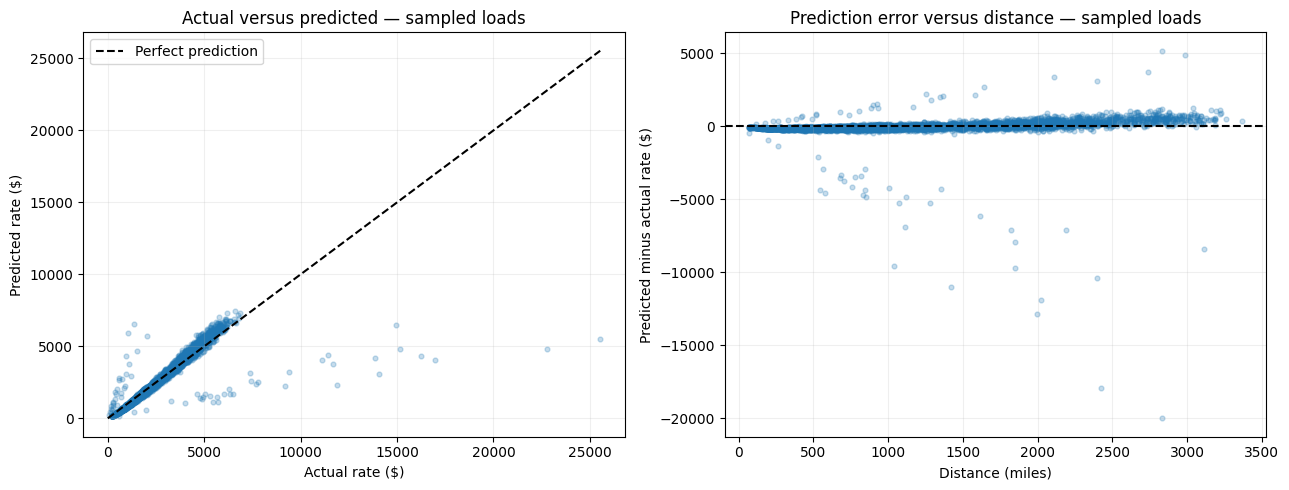

In [29]:
# Sample for visual readability only.
# All metrics and tables above use every evaluation row.
error_plot_sample = baseline_diagnostics.sample(
    n=min(5000, len(baseline_diagnostics)),
    random_state=SEED,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual versus predicted.
axes[0].scatter(
    error_plot_sample["actual_rate"],
    error_plot_sample["predicted_rate"],
    s=12,
    alpha=0.25,
)

upper_limit = max(
    error_plot_sample["actual_rate"].max(),
    error_plot_sample["predicted_rate"].max(),
)

axes[0].plot(
    [0, upper_limit],
    [0, upper_limit],
    linestyle="--",
    color="black",
    label="Perfect prediction",
)

axes[0].set_title("Actual versus predicted — sampled loads")
axes[0].set_xlabel("Actual rate ($)")
axes[0].set_ylabel("Predicted rate ($)")
axes[0].legend()

# Signed error versus distance.
axes[1].scatter(
    error_plot_sample["distance"],
    error_plot_sample["error"],
    s=12,
    alpha=0.25,
)

axes[1].axhline(
    0,
    linestyle="--",
    color="black",
)

axes[1].set_title("Prediction error versus distance — sampled loads")
axes[1].set_xlabel("Distance (miles)")
axes[1].set_ylabel("Predicted minus actual rate ($)")

for axis in axes:
    axis.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "baseline_error_diagnostics.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

our results give us a reason to improve the pricing formula:
- Short trips are consistently underpriced.
- Trips above 2,000 miles are overpriced by about $299 on average.
- About 1% of loads contribute 88% of squared error, so extreme mistakes strongly affect RMSE.
We’ll now try:
\[
\text{Predicted rate} = \text{fixed charge} + \text{distance} \times \text{mileage rate}
\]
Both the fixed charge and mileage rate can differ by equipment.
We’ll fit Ridge, a regularized linear regression, and Huber

##Prepare the features and models

In [30]:
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, HuberRegressor

print("scikit-learn:", sklearn.__version__)


def make_linear_features(frame):
    distance = frame["distance"] / 1000.0

    # Dry Van is the reference category.
    reefer = frame["equipment"].eq("Reefer").astype(float)
    flatbed = frame["equipment"].eq("Flatbed").astype(float)

    allowed_equipment = {"Dry Van", "Reefer", "Flatbed"}
    if not frame["equipment"].isin(allowed_equipment).all():
        raise ValueError("Unexpected equipment category.")

    return pd.DataFrame({
        "distance_1000_miles": distance,
        "is_reefer": reefer,
        "is_flatbed": flatbed,
        "reefer_distance": reefer * distance,
        "flatbed_distance": flatbed * distance,
    }, index=frame.index)


linear_candidates = {
    "ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0),
    ),
    "huber": make_pipeline(
        StandardScaler(),
        HuberRegressor(
            epsilon=1.35,
            alpha=0.0001,
            max_iter=1000,
        ),
    ),
}

display(make_linear_features(train_df).head())

scikit-learn: 1.6.1


,distance_1000_miles,is_reefer,is_flatbed,reefer_distance,flatbed_distance
0,0.2743,0.0,0.0,0.0000,0.0
1,0.2805,1.0,0.0,0.2805,0.0
2,0.9678,0.0,0.0,0.0000,0.0
3,0.9654,0.0,0.0,0.0000,0.0
4,0.5419,1.0,0.0,0.5419,0.0


##Train and evaluate

We’ll temporarily express the target in thousands of dollars for numerical convenience, then convert predictions back to dollars.
A $1 prediction floor ensures positive rates. We’ll count any predictions affected by it rather than hide the adjustment.

In [31]:
linear_metric_records = []
linear_prediction_parts = []
fitted_linear_models = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]
    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]]
    evaluation_data = train_df.loc[fold["eval_idx"]]

    X_train = make_linear_features(fitting_data)
    X_eval = make_linear_features(evaluation_data)

    y_train = fitting_data[TARGET] / 1000.0

    fitted_linear_models[fold_name] = {}

    for model_name, candidate in linear_candidates.items():
        # Fresh model and scaler for each fold.
        model = clone(candidate)
        model.fit(X_train, y_train)

        raw_predictions = model.predict(X_eval) * 1000.0

        assert np.isfinite(raw_predictions).all()

        predicted = np.maximum(raw_predictions, 1.0)

        linear_metric_records.append({
            "fold": fold_name,
            "model": model_name,
            "predictions_below_floor": int(
                (raw_predictions < 1.0).sum()
            ),
            **regression_metrics(
                evaluation_data[TARGET], predicted
            ),
        })

        predictions = evaluation_data[
            ["load_id", "date", "equipment", "distance", TARGET]
        ].rename(columns={TARGET: "actual_rate"}).copy()

        predictions["fold"] = fold_name
        predictions["model"] = model_name
        predictions["predicted_rate"] = predicted
        predictions["error"] = (
            predicted - predictions["actual_rate"]
        )
        predictions["absolute_error"] = (
            predictions["error"].abs()
        )

        linear_prediction_parts.append(predictions)
        fitted_linear_models[fold_name][model_name] = model

        print(f"Finished {fold_name}: {model_name}")

linear_results = pd.DataFrame(linear_metric_records)

linear_oof = pd.concat(
    linear_prediction_parts, ignore_index=True
)

assert not linear_oof.duplicated(
    subset=["model", "load_id"]
).any()

display(linear_results.round(2))

Finished fold_A: ridge
Finished fold_A: huber
Finished fold_B: ridge
Finished fold_B: huber
Finished fold_C: ridge
Finished fold_C: huber


,fold,model,predictions_below_floor,MAE,RMSE,WAPE_pct,bias
0,fold_A,ridge,0,160.70,552.95,6.77,-103.76
1,fold_A,huber,0,169.33,556.54,7.14,-126.05
2,fold_B,ridge,0,195.74,661.00,7.96,-149.84
3,fold_B,huber,0,207.43,665.14,8.44,-171.87
4,fold_C,ridge,0,143.66,632.06,6.04,-22.61
5,fold_C,huber,0,142.06,633.16,5.98,-47.56


##Compare against the previous baselines

In [32]:
comparison_oof = pd.concat(
    [baseline_oof, linear_oof],
    ignore_index=True,
)

# Verify that every model was evaluated on the same loads.
expected_ids = set(
    baseline_oof.loc[
        baseline_oof["model"].eq("equipment_mileage"),
        "load_id",
    ]
)

comparison_records = []

for model_name, predictions in comparison_oof.groupby("model"):
    assert predictions["load_id"].is_unique
    assert set(predictions["load_id"]) == expected_ids

    comparison_records.append({
        "model": model_name,
        "evaluated_loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

model_comparison = (
    pd.DataFrame(comparison_records)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Pooled comparison — lower MAE and RMSE are better:")
display(model_comparison.round(2))

print("\nMAE by fold:")
display(
    pd.concat(
        [baseline_results, linear_results],
        ignore_index=True,
    )
    .pivot(index="fold", columns="model", values="MAE")
    .round(2)
)

linear_results.to_csv(
    OUTPUT_DIR / "linear_fold_metrics.csv", index=False
)
linear_oof.to_csv(
    OUTPUT_DIR / "linear_oof_predictions.csv", index=False
)
model_comparison.to_csv(
    OUTPUT_DIR / "baseline_linear_comparison.csv", index=False
)

Pooled comparison — lower MAE and RMSE are better:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,ridge,29222,166.69,616.69,6.94,-92.20
1,huber,29222,172.95,619.62,7.20,-115.28
2,equipment_mileage,29222,206.56,626.69,8.60,-32.86
3,constant_median,29222,1143.53,1557.16,47.59,-414.27



MAE by fold:


model,constant_median,equipment_mileage,huber,ridge
fold,,,,
fold_A,1126.74,191.06,169.33,160.70
fold_B,1175.96,206.18,207.43,195.74
fold_C,1128.11,222.73,142.06,143.66


#Saving progress

In [33]:
import pickle
import shutil
from google.colab import files

variables_to_save = [
    "SEED", "TARGET", "FEATURE_COLUMNS", "NUMERIC_FEATURES",
    "train_raw", "inference_raw", "template_raw", "december_raw",
    "train_df", "inference_df",
    "folds", "DEVELOPMENT_FOLDS", "RESERVED_FOLD",
    "baseline_oof", "baseline_results",
    "linear_oof", "linear_results",
]

checkpoint = {
    name: globals()[name]
    for name in variables_to_save
}

with open(PROJECT_DIR / "checkpoint.pkl", "wb") as handle:
    pickle.dump(checkpoint, handle)

archive_path = shutil.make_archive(
    "/content/freight_checkpoint",
    "zip",
    root_dir=PROJECT_DIR,
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Restore on GPU

In [1]:
import pickle
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from google.colab import files

PROJECT_DIR = Path("/content/freight_rate_project")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

assert len(uploaded) == 1, "Upload only freight_checkpoint.zip."
archive_name = next(iter(uploaded))

with zipfile.ZipFile(archive_name) as archive:
    archive.extractall(PROJECT_DIR)

# Restore the checkpoint created by your own notebook.
with open(PROJECT_DIR / "checkpoint.pkl", "rb") as handle:
    checkpoint = pickle.load(handle)

globals().update(checkpoint)

print("Restored development rows:", len(train_df))
print("Restored final inference rows:", len(inference_df))
print("Previous predictions and output files restored.")

Saving freight_checkpoint.zip to freight_checkpoint.zip
Restored development rows: 48000
Restored final inference rows: 12000
Previous predictions and output files restored.


##CatBoost & GPU

In [2]:
%pip install -q catboost

import subprocess
import catboost
from catboost import CatBoostRegressor

print("CatBoost version:", catboost.__version__)

gpu_check = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(gpu_check.stdout)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.1 MB/s eta 0:00:00
CatBoost version: 1.2.10
Wed Oct  7 13:53:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                    

##Catboost features

In [3]:
CAT_FEATURES = [
    "pickup",
    "delivery",
    "equipment",
    "weekday",
]


def make_catboost_features(frame):
    columns = [
        "pickup", "delivery", "equipment",
        "pickup_lat", "pickup_lon",
        "delivery_lat", "delivery_lon",
        "distance", "weight",
        "weight_was_missing", "weight_was_invalid",
    ]

    features = frame[columns].copy()

    features["weekday"] = (
        pd.to_datetime(frame["date"])
        .dt.dayofweek
        .astype(str)
    )

    for column in CAT_FEATURES:
        features[column] = (
            features[column]
            .fillna("__MISSING__")
            .astype(str)
        )

    return features


display(make_catboost_features(train_df).head())

,pickup,delivery,equipment,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,weight_was_missing,weight_was_invalid,weekday
0,Richmond,Baltimore,Dry Van,38.09122,-76.78906,38.16908,-72.74564,274.3,30658.0,0,0,2
1,Richmond,Philadelphia,Reefer,38.09122,-76.78906,39.22317,-72.96710,280.5,17555.0,0,0,2
2,Philadelphia,Green Bay,Dry Van,39.22317,-72.96710,44.30296,-87.52871,967.8,31721.0,0,0,2
3,Hartford,Atlanta,Dry Van,39.55328,-72.18051,34.84933,-86.28940,965.4,32333.0,0,0,2
4,Dallas,Nashville,Reefer,31.83025,-94.38343,35.29479,-88.08915,541.9,35183.0,0,0,2


In [5]:
import numpy as np

def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if actual.ndim != 1 or actual.shape != predicted.shape:
        raise ValueError("Actual and predicted must be matching 1D arrays.")

    if len(actual) == 0:
        raise ValueError("Cannot evaluate empty predictions.")

    if not np.isfinite(actual).all():
        raise ValueError("Actual rates contain missing or infinite values.")

    if not np.isfinite(predicted).all():
        raise ValueError("Predictions contain missing or infinite values.")

    if (actual <= 0).any():
        raise ValueError("Expected positive actual shipment rates.")

    error = predicted - actual

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": (
            100 * np.sum(np.abs(error)) / np.sum(np.abs(actual))
        ),
        "bias": np.mean(error),
    }

print("regression_metrics is ready.")

regression_metrics is ready.


##Train

We’ll start with:
- Pickup, delivery, and equipment.
- Coordinates, distance, and cleaned weight.
- Weight-quality indicators.
- Day of the week.
We’ll initially leave out quote_signal and market_index. This establishes a model using core shipment information, which we can later enrich through controlled comparisons.
CatBoost handles numerical missing values, so weight can remain NaN

There is one extra step: early stopping, which selects how many trees to build. To keep evaluation honest:
1. Temporarily reserve the last 14 days of each training window for early stopping.
2. Select the tree count.
3. Retrain on the entire training window using that count.
4. Predict the outer evaluation period.

In [6]:
CB_PARAMS = {
    "task_type": "GPU",
    "devices": "0",
    "depth": 6,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5,
    "loss_function": "RMSE",
    "eval_metric": "MAE",
    "random_seed": SEED,
    "allow_writing_files": False,
}

catboost_records = []
catboost_prediction_parts = []
catboost_models = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]
    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]].copy()
    evaluation_data = train_df.loc[fold["eval_idx"]].copy()

    # Last 14 calendar days inside the training window.
    inner_cutoff = (
        fitting_data["date"].max() - pd.Timedelta(days=13)
    )

    inner_train = fitting_data.loc[
        fitting_data["date"] < inner_cutoff
    ]
    inner_validation = fitting_data.loc[
        fitting_data["date"] >= inner_cutoff
    ]

    assert len(inner_train) > 0 and len(inner_validation) > 0
    assert (
        inner_train["date"].max()
        < inner_validation["date"].min()
    )

    print(f"\n{fold_name}: selecting tree count...")

    stopping_model = CatBoostRegressor(
        **CB_PARAMS,
        iterations=2000,
    )

    stopping_model.fit(
        make_catboost_features(inner_train),
        inner_train[TARGET],
        cat_features=CAT_FEATURES,
        eval_set=(
            make_catboost_features(inner_validation),
            inner_validation[TARGET],
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=250,
    )

    # CatBoost reports a zero-based best iteration.
    best_iterations = stopping_model.get_best_iteration() + 1
    assert best_iterations > 0

    print(
        f"{fold_name}: refitting on all training rows "
        f"with {best_iterations} trees."
    )

    model = CatBoostRegressor(
        **CB_PARAMS,
        iterations=best_iterations,
    )

    model.fit(
        make_catboost_features(fitting_data),
        fitting_data[TARGET],
        cat_features=CAT_FEATURES,
        verbose=False,
    )

    raw_predictions = model.predict(
        make_catboost_features(evaluation_data)
    )

    assert np.isfinite(raw_predictions).all()

    # Same positivity rule used for Ridge and Huber.
    predicted = np.maximum(raw_predictions, 1.0)

    catboost_records.append({
        "fold": fold_name,
        "model": "catboost_core",
        "trees": best_iterations,
        "predictions_below_floor": int(
            (raw_predictions < 1.0).sum()
        ),
        **regression_metrics(
            evaluation_data[TARGET], predicted
        ),
    })

    predictions = evaluation_data[
        ["load_id", "date", "equipment", "distance", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["fold"] = fold_name
    predictions["model"] = "catboost_core"
    predictions["predicted_rate"] = predicted
    predictions["error"] = (
        predicted - predictions["actual_rate"]
    )
    predictions["absolute_error"] = predictions["error"].abs()

    catboost_prediction_parts.append(predictions)
    catboost_models[fold_name] = model

    model.save_model(
        str(OUTPUT_DIR / f"catboost_core_{fold_name}.cbm")
    )

catboost_results = pd.DataFrame(catboost_records)

catboost_oof = pd.concat(
    catboost_prediction_parts,
    ignore_index=True,
)

display(catboost_results.round(2))


fold_A: selecting tree count...
0:	learn: 1055.3070114	test: 1021.9078578	best: 1021.9078578 (0)	total: 27.3ms	remaining: 54.6s


Default metric period is 5 because MAE is/are not implemented for GPU


250:	learn: 108.3034723	test: 99.4066154	best: 99.0164143 (218)	total: 5.34s	remaining: 37.2s
bestTest = 99.01641429
bestIteration = 218
Shrink model to first 219 iterations.
fold_A: refitting on all training rows with 219 trees.


Default metric period is 5 because MAE is/are not implemented for GPU



fold_B: selecting tree count...


...


fold_C: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1097.7799306	test: 1161.1949078	best: 1161.1949078 (0)	total: 23.2ms	remaining: 46.4s
250:	learn: 130.3376998	test: 215.3403205	best: 215.3083160 (241)	total: 5.8s	remaining: 40.4s
bestTest = 214.9724539
bestIteration = 287
Shrink model to first 288 iterations.
fold_C: refitting on all training rows with 288 trees.


Default metric period is 5 because MAE is/are not implemented for GPU


,fold,model,trees,predictions_below_floor,MAE,RMSE,WAPE_pct,bias
0,fold_A,catboost_core,219,0,147.31,550.18,6.21,-104.85
1,fold_B,catboost_core,325,0,179.81,658.47,7.31,-146.85
2,fold_C,catboost_core,288,0,119.24,625.62,5.02,-16.82


##Model Comparison

In [7]:
comparison_oof = pd.concat(
    [baseline_oof, linear_oof, catboost_oof],
    ignore_index=True,
)

expected_ids = set(
    baseline_oof.loc[
        baseline_oof["model"].eq("equipment_mileage"),
        "load_id",
    ]
)

comparison_records = []

for model_name, predictions in comparison_oof.groupby("model"):
    assert predictions["load_id"].is_unique
    assert set(predictions["load_id"]) == expected_ids

    comparison_records.append({
        "model": model_name,
        "evaluated_loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

model_comparison = (
    pd.DataFrame(comparison_records)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Pooled comparison:")
display(model_comparison.round(2))

print("\nMAE by fold:")
display(
    pd.concat(
        [baseline_results, linear_results, catboost_results],
        ignore_index=True,
    )
    .pivot(index="fold", columns="model", values="MAE")
    .round(2)
)

catboost_results.to_csv(
    OUTPUT_DIR / "catboost_core_fold_metrics.csv", index=False
)
catboost_oof.to_csv(
    OUTPUT_DIR / "catboost_core_oof_predictions.csv", index=False
)
model_comparison.to_csv(
    OUTPUT_DIR / "comparison_with_catboost.csv", index=False
)

Pooled comparison:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,catboost_core,29222,148.80,612.77,6.19,-89.65
1,ridge,29222,166.69,616.69,6.94,-92.20
2,huber,29222,172.95,619.62,7.20,-115.28
3,equipment_mileage,29222,206.56,626.69,8.60,-32.86
4,constant_median,29222,1143.53,1557.16,47.59,-414.27



MAE by fold:


model,catboost_core,constant_median,equipment_mileage,huber,ridge
fold,,,,,
fold_A,147.31,1126.74,191.06,169.33,160.70
fold_B,179.81,1175.96,206.18,207.43,195.74
fold_C,119.24,1128.11,222.73,142.06,143.66


##CatBoost is now our strongest candidate:
- MAE improved by 10.7% over Ridge, from $166.69 to $148.80.
- It improved on Ridge in all three folds.
- RMSE improved only slightly, so large errors remain.
- Bias is still about −$90: it underprices loads on average.
Next, we’ll make one change: add market_index. This tells us whether the supplied market information improves future-period predictions. We’ll keep the training settings and evaluation procedure the same.
We’ll retain the core model separately because the December chart does not supply a market index. If this richer model wins, we’ll address that missing-input case before finalizing the solution.

##Train Catboost with market_index

In [8]:
def make_market_features(frame):
    features = make_catboost_features(frame)

    features["market_index"] = frame["market_index"]
    features["market_index_was_missing"] = (
        frame["market_index_was_missing"]
    )

    return features


market_records = []
market_prediction_parts = []
market_models = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]
    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]].copy()
    evaluation_data = train_df.loc[fold["eval_idx"]].copy()

    # Same inner validation procedure as the core model.
    inner_cutoff = (
        fitting_data["date"].max() - pd.Timedelta(days=13)
    )

    inner_train = fitting_data.loc[
        fitting_data["date"] < inner_cutoff
    ]
    inner_validation = fitting_data.loc[
        fitting_data["date"] >= inner_cutoff
    ]

    print(f"\n{fold_name}: selecting tree count...")

    stopping_model = CatBoostRegressor(
        **CB_PARAMS,
        iterations=2000,
    )

    stopping_model.fit(
        make_market_features(inner_train),
        inner_train[TARGET],
        cat_features=CAT_FEATURES,
        eval_set=(
            make_market_features(inner_validation),
            inner_validation[TARGET],
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    best_iterations = stopping_model.get_best_iteration() + 1
    assert best_iterations > 0

    # Refit on the entire outer training partition.
    model = CatBoostRegressor(
        **CB_PARAMS,
        iterations=best_iterations,
    )

    model.fit(
        make_market_features(fitting_data),
        fitting_data[TARGET],
        cat_features=CAT_FEATURES,
        verbose=False,
    )

    raw_predictions = model.predict(
        make_market_features(evaluation_data)
    )

    assert np.isfinite(raw_predictions).all()
    predicted = np.maximum(raw_predictions, 1.0)

    metrics = regression_metrics(
        evaluation_data[TARGET], predicted
    )

    market_records.append({
        "fold": fold_name,
        "model": "catboost_market",
        "trees": best_iterations,
        "predictions_below_floor": int(
            (raw_predictions < 1.0).sum()
        ),
        **metrics,
    })

    predictions = evaluation_data[
        ["load_id", "date", "equipment", "distance", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["fold"] = fold_name
    predictions["model"] = "catboost_market"
    predictions["predicted_rate"] = predicted
    predictions["error"] = (
        predicted - predictions["actual_rate"]
    )
    predictions["absolute_error"] = predictions["error"].abs()

    market_prediction_parts.append(predictions)
    market_models[fold_name] = model

    model.save_model(
        str(OUTPUT_DIR / f"catboost_market_{fold_name}.cbm")
    )

    print(
        f"{fold_name}: {best_iterations} trees, "
        f"MAE ${metrics['MAE']:.2f}"
    )

market_results = pd.DataFrame(market_records)

market_oof = pd.concat(
    market_prediction_parts,
    ignore_index=True,
)

display(market_results.round(2))


fold_A: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_A: 220 trees, MAE $131.10

fold_B: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_B: 605 trees, MAE $134.79

fold_C: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_C: 683 trees, MAE $111.92


,fold,model,trees,predictions_below_floor,MAE,RMSE,WAPE_pct,bias
0,fold_A,catboost_market,220,0,131.10,542.99,5.53,-76.62
1,fold_B,catboost_market,605,0,134.79,644.57,5.48,-55.72
2,fold_C,catboost_market,683,0,111.92,626.19,4.71,-43.28


##Compare and Save

In [9]:
comparison_oof = pd.concat(
    [baseline_oof, linear_oof, catboost_oof, market_oof],
    ignore_index=True,
)

expected_ids = set(catboost_oof["load_id"])
comparison_records = []

for model_name, predictions in comparison_oof.groupby("model"):
    assert predictions["load_id"].is_unique
    assert set(predictions["load_id"]) == expected_ids

    comparison_records.append({
        "model": model_name,
        "evaluated_loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

model_comparison = (
    pd.DataFrame(comparison_records)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Pooled comparison:")
display(model_comparison.round(2))

print("\nCore versus market model — MAE by fold:")
display(
    pd.concat(
        [catboost_results, market_results],
        ignore_index=True,
    )
    .pivot(index="fold", columns="model", values="MAE")
    .round(2)
)

market_results.to_csv(
    OUTPUT_DIR / "catboost_market_fold_metrics.csv",
    index=False,
)
market_oof.to_csv(
    OUTPUT_DIR / "catboost_market_oof_predictions.csv",
    index=False,
)
model_comparison.to_csv(
    OUTPUT_DIR / "comparison_with_market.csv",
    index=False,
)

Pooled comparison:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,catboost_market,29222,125.98,605.85,5.24,-58.65
1,catboost_core,29222,148.80,612.77,6.19,-89.65
2,ridge,29222,166.69,616.69,6.94,-92.20
3,huber,29222,172.95,619.62,7.20,-115.28
4,equipment_mileage,29222,206.56,626.69,8.60,-32.86
5,constant_median,29222,1143.53,1557.16,47.59,-414.27



Core versus market model — MAE by fold:


model,catboost_core,catboost_market
fold,,
fold_A,147.31,131.10
fold_B,179.81,134.79
fold_C,119.24,111.92


Your results support keeping market_index:
- Pooled MAE improved from $148.80 to $125.98, a 15.3% improvement.
- All three folds improved.
- RMSE and underprediction bias also improved.

##Train the MAE-loss candidate

In [10]:
# Keep the previous RMSE configuration unchanged.
ROBUST_PARAMS = {
    **CB_PARAMS,
    "loss_function": "MAE",
}

robust_records = []
robust_prediction_parts = []
robust_models = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]
    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]].copy()
    evaluation_data = train_df.loc[fold["eval_idx"]].copy()

    inner_cutoff = (
        fitting_data["date"].max() - pd.Timedelta(days=13)
    )

    inner_train = fitting_data.loc[
        fitting_data["date"] < inner_cutoff
    ]
    inner_validation = fitting_data.loc[
        fitting_data["date"] >= inner_cutoff
    ]

    print(f"\n{fold_name}: selecting tree count...")

    stopping_model = CatBoostRegressor(
        **ROBUST_PARAMS,
        iterations=2000,
    )

    stopping_model.fit(
        make_market_features(inner_train),
        inner_train[TARGET],
        cat_features=CAT_FEATURES,
        eval_set=(
            make_market_features(inner_validation),
            inner_validation[TARGET],
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    best_iterations = stopping_model.get_best_iteration() + 1
    assert best_iterations > 0

    model = CatBoostRegressor(
        **ROBUST_PARAMS,
        iterations=best_iterations,
    )

    model.fit(
        make_market_features(fitting_data),
        fitting_data[TARGET],
        cat_features=CAT_FEATURES,
        verbose=False,
    )

    raw_predictions = model.predict(
        make_market_features(evaluation_data)
    )

    assert np.isfinite(raw_predictions).all()
    predicted = np.maximum(raw_predictions, 1.0)

    metrics = regression_metrics(
        evaluation_data[TARGET], predicted
    )

    robust_records.append({
        "fold": fold_name,
        "model": "catboost_market_mae",
        "trees": best_iterations,
        "predictions_below_floor": int(
            (raw_predictions < 1.0).sum()
        ),
        **metrics,
    })

    predictions = evaluation_data[
        ["load_id", "date", "equipment", "distance", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["fold"] = fold_name
    predictions["model"] = "catboost_market_mae"
    predictions["predicted_rate"] = predicted
    predictions["error"] = (
        predicted - predictions["actual_rate"]
    )
    predictions["absolute_error"] = predictions["error"].abs()

    robust_prediction_parts.append(predictions)
    robust_models[fold_name] = model

    model.save_model(
        str(OUTPUT_DIR / f"catboost_market_mae_{fold_name}.cbm")
    )

    print(
        f"{fold_name}: {best_iterations} trees, "
        f"MAE ${metrics['MAE']:.2f}, "
        f"RMSE ${metrics['RMSE']:.2f}"
    )

robust_results = pd.DataFrame(robust_records)

robust_oof = pd.concat(
    robust_prediction_parts,
    ignore_index=True,
)

display(robust_results.round(2))


fold_A: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_A: 2000 trees, MAE $1082.84, RMSE $1487.16

fold_B: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_B: 2000 trees, MAE $1132.43, RMSE $1582.09

fold_C: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_C: 2000 trees, MAE $1083.60, RMSE $1497.57


,fold,model,trees,predictions_below_floor,MAE,RMSE,WAPE_pct,bias
0,fold_A,catboost_market_mae,2000,0,1082.84,1487.16,45.65,-420.65
1,fold_B,catboost_market_mae,2000,0,1132.43,1582.09,46.05,-467.52
2,fold_C,catboost_market_mae,2000,0,1083.60,1497.57,45.58,-354.99


##Compare

In [11]:
comparison_oof = pd.concat(
    [
        baseline_oof,
        linear_oof,
        catboost_oof,
        market_oof,
        robust_oof,
    ],
    ignore_index=True,
)

expected_ids = set(market_oof["load_id"])
comparison_records = []

for model_name, predictions in comparison_oof.groupby("model"):
    assert predictions["load_id"].is_unique
    assert set(predictions["load_id"]) == expected_ids

    comparison_records.append({
        "model": model_name,
        "evaluated_loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

model_comparison = (
    pd.DataFrame(comparison_records)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Pooled comparison:")
display(model_comparison.round(2))

print("\nRMSE-loss versus MAE-loss CatBoost, by fold:")
display(
    pd.concat(
        [market_results, robust_results],
        ignore_index=True,
    )[
        ["fold", "model", "trees", "MAE", "RMSE", "bias"]
    ]
    .sort_values(["fold", "model"])
    .round(2)
)

robust_results.to_csv(
    OUTPUT_DIR / "catboost_market_mae_fold_metrics.csv",
    index=False,
)
robust_oof.to_csv(
    OUTPUT_DIR / "catboost_market_mae_oof_predictions.csv",
    index=False,
)
model_comparison.to_csv(
    OUTPUT_DIR / "comparison_with_mae_loss.csv",
    index=False,
)

Pooled comparison:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,catboost_market,29222,125.98,605.85,5.24,-58.65
1,catboost_core,29222,148.80,612.77,6.19,-89.65
2,ridge,29222,166.69,616.69,6.94,-92.20
3,huber,29222,172.95,619.62,7.20,-115.28
4,equipment_mileage,29222,206.56,626.69,8.60,-32.86
5,catboost_market_mae,29222,1099.55,1522.70,45.76,-414.47
6,constant_median,29222,1143.53,1557.16,47.59,-414.27



RMSE-loss versus MAE-loss CatBoost, by fold:


,fold,model,trees,MAE,RMSE,bias
0,fold_A,catboost_market,220,131.10,542.99,-76.62
3,fold_A,catboost_market_mae,2000,1082.84,1487.16,-420.65
1,fold_B,catboost_market,605,134.79,644.57,-55.72
4,fold_B,catboost_market_mae,2000,1132.43,1582.09,-467.52
2,fold_C,catboost_market,683,111.92,626.19,-43.28
5,fold_C,catboost_market_mae,2000,1083.60,1497.57,-354.99


In [12]:
import catboost

print("CatBoost version:", catboost.__version__)

diagnostic_records = []

for fold_name in DEVELOPMENT_FOLDS:
    model = robust_models[fold_name]
    params = model.get_all_params()

    fitting_data = train_df.loc[folds[fold_name]["train_idx"]]

    training_predictions = model.predict(
        make_market_features(fitting_data)
    )

    diagnostic_records.append({
        "fold": fold_name,
        "task_type": params.get("task_type"),
        "boosting_type": params.get("boosting_type"),
        "leaf_estimation_method": params.get("leaf_estimation_method"),
        "leaf_estimation_iterations": params.get(
            "leaf_estimation_iterations"
        ),
        "learning_rate": params.get("learning_rate"),
        "trees": model.tree_count_,
        "training_MAE": np.mean(
            np.abs(
                training_predictions
                - fitting_data[TARGET].to_numpy()
            )
        ),
        "prediction_p05": np.quantile(training_predictions, 0.05),
        "prediction_p95": np.quantile(training_predictions, 0.95),
        "actual_p05": fitting_data[TARGET].quantile(0.05),
        "actual_p95": fitting_data[TARGET].quantile(0.95),
    })

display(pd.DataFrame(diagnostic_records).round(3))


CatBoost version: 1.2.10


,fold,task_type,boosting_type,leaf_estimation_method,leaf_estimation_iterations,learning_rate,trees,training_MAE,prediction_p05,prediction_p95,actual_p05,actual_p95
0,fold_A,GPU,Ordered,Gradient,1,0.05,2000,1022.393,1902.517,2000.728,589.715,4688.814
1,fold_B,GPU,Ordered,Gradient,1,0.05,2000,1052.820,1941.971,2040.403,597.684,4832.106
2,fold_C,GPU,Ordered,Gradient,1,0.05,2000,1079.071,1973.542,2072.112,597.308,4930.262


##Correct MAE

In [13]:
MAE_TARGET_SCALE = 1000.0

SCALED_MAE_PARAMS = {
    **CB_PARAMS,
    "loss_function": "MAE",
}

scaled_mae_records = []
scaled_mae_prediction_parts = []
scaled_mae_models = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]
    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]].copy()
    evaluation_data = train_df.loc[fold["eval_idx"]].copy()

    inner_cutoff = (
        fitting_data["date"].max() - pd.Timedelta(days=13)
    )

    inner_train = fitting_data.loc[
        fitting_data["date"] < inner_cutoff
    ]
    inner_validation = fitting_data.loc[
        fitting_data["date"] >= inner_cutoff
    ]

    print(f"\n{fold_name}: selecting tree count...")

    stopping_model = CatBoostRegressor(
        **SCALED_MAE_PARAMS,
        iterations=2000,
    )

    stopping_model.fit(
        make_market_features(inner_train),
        inner_train[TARGET] / MAE_TARGET_SCALE,
        cat_features=CAT_FEATURES,
        eval_set=(
            make_market_features(inner_validation),
            inner_validation[TARGET] / MAE_TARGET_SCALE,
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    best_iterations = stopping_model.get_best_iteration() + 1
    assert best_iterations > 0

    # Refit using every row in the outer training partition.
    model = CatBoostRegressor(
        **SCALED_MAE_PARAMS,
        iterations=best_iterations,
    )

    model.fit(
        make_market_features(fitting_data),
        fitting_data[TARGET] / MAE_TARGET_SCALE,
        cat_features=CAT_FEATURES,
        verbose=False,
    )

    # Convert predictions back to dollars.
    raw_predictions = (
        model.predict(make_market_features(evaluation_data))
        * MAE_TARGET_SCALE
    )

    assert np.isfinite(raw_predictions).all()
    predicted = np.maximum(raw_predictions, 1.0)

    # Also inspect training error to check the underfitting problem.
    training_predictions = (
        model.predict(make_market_features(fitting_data))
        * MAE_TARGET_SCALE
    )

    metrics = regression_metrics(
        evaluation_data[TARGET], predicted
    )

    scaled_mae_records.append({
        "fold": fold_name,
        "model": "catboost_market_mae_scaled",
        "trees": best_iterations,
        "training_MAE": regression_metrics(
            fitting_data[TARGET], training_predictions
        )["MAE"],
        "predictions_below_floor": int(
            (raw_predictions < 1.0).sum()
        ),
        **metrics,
    })

    predictions = evaluation_data[
        ["load_id", "date", "equipment", "distance", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["fold"] = fold_name
    predictions["model"] = "catboost_market_mae_scaled"
    predictions["predicted_rate"] = predicted
    predictions["error"] = (
        predicted - predictions["actual_rate"]
    )
    predictions["absolute_error"] = predictions["error"].abs()

    scaled_mae_prediction_parts.append(predictions)
    scaled_mae_models[fold_name] = model

    model.save_model(
        str(
            OUTPUT_DIR
            / f"catboost_market_mae_scaled_{fold_name}.cbm"
        )
    )

    print(
        f"{fold_name}: {best_iterations} trees, "
        f"evaluation MAE ${metrics['MAE']:.2f}"
    )

scaled_mae_results = pd.DataFrame(scaled_mae_records)

scaled_mae_oof = pd.concat(
    scaled_mae_prediction_parts,
    ignore_index=True,
)

display(scaled_mae_results.round(2))


fold_A: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_A: 394 trees, evaluation MAE $117.01

fold_B: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_B: 311 trees, evaluation MAE $119.83

fold_C: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_C: 391 trees, evaluation MAE $108.92


,fold,model,trees,training_MAE,predictions_below_floor,MAE,RMSE,WAPE_pct,bias
0,fold_A,catboost_market_mae_scaled,394,76.20,0,117.01,540.05,4.93,-82.94
1,fold_B,catboost_market_mae_scaled,311,82.57,0,119.83,637.98,4.87,-81.48
2,fold_C,catboost_market_mae_scaled,391,89.54,0,108.92,625.55,4.58,-72.16


In [14]:
import json

comparison_oof = pd.concat(
    [
        baseline_oof,
        linear_oof,
        catboost_oof,
        market_oof,
        robust_oof,       # Retain the unsuccessful unscaled experiment.
        scaled_mae_oof,
    ],
    ignore_index=True,
)

expected_ids = set(market_oof["load_id"])
comparison_records = []

for model_name, predictions in comparison_oof.groupby("model"):
    assert predictions["load_id"].is_unique
    assert set(predictions["load_id"]) == expected_ids

    comparison_records.append({
        "model": model_name,
        "evaluated_loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

model_comparison = (
    pd.DataFrame(comparison_records)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Pooled comparison — all metrics are in original dollar units:")
display(model_comparison.round(2))

print("\nRMSE-trained versus corrected MAE-trained model:")
display(
    pd.concat(
        [market_results, scaled_mae_results],
        ignore_index=True,
    )[
        ["fold", "model", "trees", "MAE", "RMSE", "bias"]
    ]
    .sort_values(["fold", "model"])
    .round(2)
)

scaled_mae_results.to_csv(
    OUTPUT_DIR / "catboost_market_mae_scaled_fold_metrics.csv",
    index=False,
)
scaled_mae_oof.to_csv(
    OUTPUT_DIR / "catboost_market_mae_scaled_oof_predictions.csv",
    index=False,
)
model_comparison.to_csv(
    OUTPUT_DIR / "comparison_with_scaled_mae.csv",
    index=False,
)

# Save the scaling requirement alongside the trained models.
with open(
    OUTPUT_DIR / "catboost_market_mae_scaled_config.json", "w"
) as handle:
    json.dump(
        {
            "parameters": SCALED_MAE_PARAMS,
            "target_scale": MAE_TARGET_SCALE,
            "prediction_rule": "Multiply model output by target_scale, then floor at 1 dollar.",
        },
        handle,
        indent=2,
    )

Pooled comparison — all metrics are in original dollar units:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,catboost_market_mae_scaled,29222,115.27,602.42,4.80,-78.89
1,catboost_market,29222,125.98,605.85,5.24,-58.65
2,catboost_core,29222,148.80,612.77,6.19,-89.65
3,ridge,29222,166.69,616.69,6.94,-92.20
4,huber,29222,172.95,619.62,7.20,-115.28
5,equipment_mileage,29222,206.56,626.69,8.60,-32.86
6,catboost_market_mae,29222,1099.55,1522.70,45.76,-414.47
7,constant_median,29222,1143.53,1557.16,47.59,-414.27



RMSE-trained versus corrected MAE-trained model:


,fold,model,trees,MAE,RMSE,bias
0,fold_A,catboost_market,220,131.10,542.99,-76.62
3,fold_A,catboost_market_mae_scaled,394,117.01,540.05,-82.94
1,fold_B,catboost_market,605,134.79,644.57,-55.72
4,fold_B,catboost_market_mae_scaled,311,119.83,637.98,-81.48
2,fold_C,catboost_market,683,111.92,626.19,-43.28
5,fold_C,catboost_market_mae_scaled,391,108.92,625.55,-72.16


In [15]:
def make_quote_features(frame):
    features = make_market_features(frame)
    features["quote_signal"] = frame["quote_signal"]
    return features


QUOTE_PARAMS = dict(SCALED_MAE_PARAMS)
QUOTE_TARGET_SCALE = MAE_TARGET_SCALE

quote_records = []
quote_prediction_parts = []
quote_models = {}

for fold_name in DEVELOPMENT_FOLDS:
    fold = folds[fold_name]
    assert fold["purpose"] == "development"

    fitting_data = train_df.loc[fold["train_idx"]].copy()
    evaluation_data = train_df.loc[fold["eval_idx"]].copy()

    inner_cutoff = (
        fitting_data["date"].max() - pd.Timedelta(days=13)
    )

    inner_train = fitting_data.loc[
        fitting_data["date"] < inner_cutoff
    ]
    inner_validation = fitting_data.loc[
        fitting_data["date"] >= inner_cutoff
    ]

    print(f"\n{fold_name}: selecting tree count...")

    stopping_model = CatBoostRegressor(
        **QUOTE_PARAMS,
        iterations=2000,
    )

    stopping_model.fit(
        make_quote_features(inner_train),
        inner_train[TARGET] / QUOTE_TARGET_SCALE,
        cat_features=CAT_FEATURES,
        eval_set=(
            make_quote_features(inner_validation),
            inner_validation[TARGET] / QUOTE_TARGET_SCALE,
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    best_iterations = stopping_model.get_best_iteration() + 1
    assert best_iterations > 0

    model = CatBoostRegressor(
        **QUOTE_PARAMS,
        iterations=best_iterations,
    )

    model.fit(
        make_quote_features(fitting_data),
        fitting_data[TARGET] / QUOTE_TARGET_SCALE,
        cat_features=CAT_FEATURES,
        verbose=False,
    )

    # Convert model output back to dollars.
    raw_predictions = (
        model.predict(make_quote_features(evaluation_data))
        * QUOTE_TARGET_SCALE
    )

    assert np.isfinite(raw_predictions).all()
    predicted = np.maximum(raw_predictions, 1.0)

    metrics = regression_metrics(
        evaluation_data[TARGET], predicted
    )

    quote_records.append({
        "fold": fold_name,
        "model": "catboost_market_mae_quote",
        "trees": best_iterations,
        "predictions_below_floor": int(
            (raw_predictions < 1.0).sum()
        ),
        **metrics,
    })

    predictions = evaluation_data[
        ["load_id", "date", "equipment", "distance", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["fold"] = fold_name
    predictions["model"] = "catboost_market_mae_quote"
    predictions["predicted_rate"] = predicted
    predictions["error"] = (
        predicted - predictions["actual_rate"]
    )
    predictions["absolute_error"] = predictions["error"].abs()

    quote_prediction_parts.append(predictions)
    quote_models[fold_name] = model

    model.save_model(
        str(OUTPUT_DIR / f"catboost_market_mae_quote_{fold_name}.cbm")
    )

    print(
        f"{fold_name}: {best_iterations} trees, "
        f"MAE ${metrics['MAE']:.2f}"
    )

quote_results = pd.DataFrame(quote_records)

quote_oof = pd.concat(
    quote_prediction_parts,
    ignore_index=True,
)

display(quote_results.round(2))


fold_A: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_A: 301 trees, MAE $145.44

fold_B: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_B: 624 trees, MAE $106.46

fold_C: selecting tree count...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


fold_C: 596 trees, MAE $123.02


,fold,model,trees,predictions_below_floor,MAE,RMSE,WAPE_pct,bias
0,fold_A,catboost_market_mae_quote,301,0,145.44,552.26,6.13,-76.68
1,fold_B,catboost_market_mae_quote,624,0,106.46,632.34,4.33,-58.92
2,fold_C,catboost_market_mae_quote,596,0,123.02,628.19,5.17,-59.68


##quote_signal use this time

In [16]:
quote_comparison_oof = pd.concat(
    [scaled_mae_oof, quote_oof],
    ignore_index=True,
)

model_labels = {
    "catboost_market_mae_scaled": "without_quote",
    "catboost_market_mae_quote": "with_quote",
}

expected_ids = set(scaled_mae_oof["load_id"])
pooled_records = []

for model_name, predictions in quote_comparison_oof.groupby("model"):
    assert predictions["load_id"].is_unique
    assert set(predictions["load_id"]) == expected_ids

    pooled_records.append({
        "model": model_labels[model_name],
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

quote_comparison = pd.DataFrame(pooled_records)

print("Pooled comparison:")
display(quote_comparison.round(2))

fold_comparison = (
    pd.concat(
        [scaled_mae_results, quote_results],
        ignore_index=True,
    )
    .pivot(index="fold", columns="model", values="MAE")
    .rename(columns=model_labels)
)

fold_comparison["MAE_improvement_pct"] = (
    100
    * (
        1
        - fold_comparison["with_quote"]
        / fold_comparison["without_quote"]
    )
)

print("\nMAE by fold — positive improvement means quote helped:")
display(fold_comparison.round(2))

quote_comparison_oof["month"] = (
    pd.to_datetime(quote_comparison_oof["date"])
    .dt.strftime("%Y-%m")
)

monthly_records = []

for (model_name, month), predictions in (
    quote_comparison_oof.groupby(["model", "month"])
):
    monthly_records.append({
        "model": model_labels[model_name],
        "month": month,
        "loads": len(predictions),
        **regression_metrics(
            predictions["actual_rate"],
            predictions["predicted_rate"],
        ),
    })

quote_monthly_results = pd.DataFrame(monthly_records)

print("\nMAE by month:")
display(
    quote_monthly_results.pivot(
        index="month", columns="model", values="MAE"
    ).round(2)
)

quote_results.to_csv(
    OUTPUT_DIR / "quote_fold_metrics.csv", index=False
)
quote_oof.to_csv(
    OUTPUT_DIR / "quote_oof_predictions.csv", index=False
)
quote_comparison.to_csv(
    OUTPUT_DIR / "quote_pooled_comparison.csv", index=False
)
quote_monthly_results.to_csv(
    OUTPUT_DIR / "quote_monthly_metrics.csv", index=False
)

import json

with open(OUTPUT_DIR / "quote_model_config.json", "w") as handle:
    json.dump(
        {
            "parameters": QUOTE_PARAMS,
            "target_scale": QUOTE_TARGET_SCALE,
            "features": list(make_quote_features(train_df.head()).columns),
            "categorical_features": CAT_FEATURES,
            "prediction_rule": "Multiply model output by target_scale, then floor at 1 dollar.",
        },
        handle,
        indent=2,
    )

Pooled comparison:


,model,MAE,RMSE,WAPE_pct,bias
0,with_quote,125.09,605.09,5.21,-65.16
1,without_quote,115.27,602.42,4.80,-78.89



MAE by fold — positive improvement means quote helped:


model,with_quote,without_quote,MAE_improvement_pct
fold,,,
fold_A,145.44,117.01,-24.29
fold_B,106.46,119.83,11.16
fold_C,123.02,108.92,-12.95



MAE by month:


model,with_quote,without_quote
month,,
2025-03,92.42,122.41
2025-04,200.84,111.38
2025-05,82.87,89.87
2025-06,130.69,150.61
2025-07,97.30,98.99
2025-08,149.58,119.17


##Decision: exclude quote_signal.
It increased pooled MAE from $115.27 to $125.09—about 8.5% worse—and hurt two of the three folds. April is particularly concerning: MAE rose from $111.38 to $200.84.
Its bias is closer to zero, but that does not outweigh the larger absolute errors and inconsistent monthly behavior. We now have measured evidence supporting its exclusion.
Our leading candidate remains scaled-MAE CatBoost with market index, without quote signal.
Next is one focused robustness check: can it predict loads involving unfamiliar cities? About 12% of the final loads have that characteristic.
We’ll use fold C, remove four cities from its training data, and evaluate later loads involving those cities. This is a stress test, not another parameter search.

In [17]:
STRESS_FOLD = "fold_C"

original_training = train_df.loc[
    folds[STRESS_FOLD]["train_idx"]
].copy()

stress_evaluation = train_df.loc[
    folds[STRESS_FOLD]["eval_idx"]
].copy()

training_cities = sorted(
    set(original_training["pickup"])
    | set(original_training["delivery"])
)

rng = np.random.default_rng(SEED)

withheld_cities = sorted(
    rng.choice(training_cities, size=4, replace=False).tolist()
)

# Remove every training load involving these cities.
remove_from_training = (
    original_training["pickup"].isin(withheld_cities)
    | original_training["delivery"].isin(withheld_cities)
)

stress_training = original_training.loc[
    ~remove_from_training
].copy()

# Keep all evaluation rows; label the two groups for reporting.
unfamiliar_city_mask = (
    stress_evaluation["pickup"].isin(withheld_cities)
    | stress_evaluation["delivery"].isin(withheld_cities)
)

stress_evaluation["city_group"] = np.where(
    unfamiliar_city_mask,
    "withheld_city",
    "other_cities",
)

remaining_cities = (
    set(stress_training["pickup"])
    | set(stress_training["delivery"])
)

assert set(withheld_cities).isdisjoint(remaining_cities)

print("Cities withheld from training:", withheld_cities)
print("Original training rows:", len(original_training))
print("Remaining training rows:", len(stress_training))

print("\nEvaluation group sizes:")
display(
    stress_evaluation["city_group"]
    .value_counts()
    .rename("loads")
    .to_frame()
)

Cities withheld from training: ['Bakersfield', 'Indianapolis', 'Montgomery', 'Phoenix']
Original training rows: 28806
Remaining training rows: 24499

Evaluation group sizes:


,loads
city_group,
other_cities,8206
withheld_city,1465


##Train on above changes

In [18]:
inner_cutoff = (
    stress_training["date"].max() - pd.Timedelta(days=13)
)

inner_train = stress_training.loc[
    stress_training["date"] < inner_cutoff
]

inner_validation = stress_training.loc[
    stress_training["date"] >= inner_cutoff
]

assert len(inner_train) > 0 and len(inner_validation) > 0

stress_stopping_model = CatBoostRegressor(
    **SCALED_MAE_PARAMS,
    iterations=2000,
)

stress_stopping_model.fit(
    make_market_features(inner_train),
    inner_train[TARGET] / MAE_TARGET_SCALE,
    cat_features=CAT_FEATURES,
    eval_set=(
        make_market_features(inner_validation),
        inner_validation[TARGET] / MAE_TARGET_SCALE,
    ),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=False,
)

stress_tree_count = (
    stress_stopping_model.get_best_iteration() + 1
)

assert stress_tree_count > 0

stress_model = CatBoostRegressor(
    **SCALED_MAE_PARAMS,
    iterations=stress_tree_count,
)

stress_model.fit(
    make_market_features(stress_training),
    stress_training[TARGET] / MAE_TARGET_SCALE,
    cat_features=CAT_FEATURES,
    verbose=False,
)

print("Stress-test model trained with", stress_tree_count, "trees.")

Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


Stress-test model trained with 446 trees.


In [20]:
def fit_baselines(fitting_data):
    rate_per_mile = (
        fitting_data[TARGET] / fitting_data["distance"]
    )

    equipment_medians = (
        pd.DataFrame({
            "equipment": fitting_data["equipment"],
            "rate_per_mile": rate_per_mile,
        })
        .groupby("equipment")["rate_per_mile"]
        .median()
        .to_dict()
    )

    return {
        "median_total_rate": float(fitting_data[TARGET].median()),
        "global_median_rpm": float(rate_per_mile.median()),
        "equipment_median_rpm": equipment_medians,
    }


def predict_baselines(parameters, features):
    equipment_rpm = (
        features["equipment"]
        .map(parameters["equipment_median_rpm"])
        .fillna(parameters["global_median_rpm"])
    )

    predictions = {
        "constant_median": np.full(
            len(features),
            parameters["median_total_rate"],
            dtype=float,
        ),
        "equipment_mileage": (
            features["distance"] * equipment_rpm
        ).to_numpy(dtype=float),
    }

    for name, values in predictions.items():
        if not np.isfinite(values).all() or (values <= 0).any():
            raise ValueError(f"Invalid predictions from {name}.")

    return predictions


print("Both baseline functions are restored.")

Both baseline functions are restored.


Restore Baseline above

In [21]:
stress_baseline_parameters = fit_baselines(stress_training)

stress_baseline_predictions = predict_baselines(
    stress_baseline_parameters,
    stress_evaluation[["distance", "equipment"]],
)["equipment_mileage"]

stress_raw_predictions = (
    stress_model.predict(
        make_market_features(stress_evaluation)
    )
    * MAE_TARGET_SCALE
)

original_raw_predictions = (
    scaled_mae_models[STRESS_FOLD].predict(
        make_market_features(stress_evaluation)
    )
    * MAE_TARGET_SCALE
)

assert np.isfinite(stress_raw_predictions).all()
assert np.isfinite(original_raw_predictions).all()

prediction_sets = {
    "mileage_reduced_training": stress_baseline_predictions,
    "catboost_reduced_training": np.maximum(
        stress_raw_predictions, 1.0
    ),
    "catboost_original_training_reference": np.maximum(
        original_raw_predictions, 1.0
    ),
}

stress_records = []
stress_prediction_parts = []

for model_name, predicted in prediction_sets.items():
    predictions = stress_evaluation[
        ["load_id", "date", "city_group", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["model"] = model_name
    predictions["predicted_rate"] = predicted

    stress_prediction_parts.append(predictions)

    for group_name, group in predictions.groupby("city_group"):
        stress_records.append({
            "model": model_name,
            "city_group": group_name,
            "loads": len(group),
            **regression_metrics(
                group["actual_rate"],
                group["predicted_rate"],
            ),
        })

stress_results = pd.DataFrame(stress_records)

display(
    stress_results.sort_values(
        ["city_group", "model"]
    ).round(2)
)

stress_results.to_csv(
    OUTPUT_DIR / "unfamiliar_city_stress_metrics.csv",
    index=False,
)

pd.concat(
    stress_prediction_parts, ignore_index=True
).to_csv(
    OUTPUT_DIR / "unfamiliar_city_stress_predictions.csv",
    index=False,
)

pd.DataFrame({"withheld_city": withheld_cities}).to_csv(
    OUTPUT_DIR / "stress_withheld_cities.csv",
    index=False,
)

,model,city_group,loads,MAE,RMSE,WAPE_pct,bias
4,catboost_original_training_reference,other_cities,8206,103.11,574.52,4.54,-68.87
2,catboost_reduced_training,other_cities,8206,103.42,574.92,4.55,-69.87
0,mileage_reduced_training,other_cities,8206,210.07,613.11,9.25,36.25
5,catboost_original_training_reference,withheld_city,1465,141.49,856.93,4.75,-90.57
3,catboost_reduced_training,withheld_city,1465,144.38,856.23,4.85,-88.43
1,mileage_reduced_training,withheld_city,1465,328.22,907.88,11.03,148.54


Your unfamiliar-city test supports the chosen model:
On withheld-city loads	MAE
Mileage baseline	$328.22
CatBoost without earlier examples of those cities	$144.38
CatBoost with earlier examples	$141.49


Removing those cities from training increased CatBoost’s MAE by only $2.89, while it still beat the mileage baseline by about 56%. That is encouraging evidence from this stress test.
Our selected model recipe is:
- CatBoost with MAE training loss.
- Targets divided by 1,000 during training; predictions converted back to dollars.
- Shipment features, coordinates, weekday, and market index.
- No quote signal.
- The existing chronological early-stopping procedure.
Its development performance is $115.27 MAE, $602.42 RMSE, and 4.80% WAPE. These are development estimates, not guaranteed November–December results.
Three execution blocks remain:
Block	What happens
1. Final validation	Train through August and evaluate September–October using the frozen recipe. No further tuning unless we uncover an implementation failure.
2. Final training and predictions	Refit using all 48,000 labeled loads; predict all 12,000 final loads. Refit the already-tested core model for December chart inputs, which lack market index.
3. Submission artifacts	Validate both prediction files, run the supplied score.py, and produce the report with its December chart and reproducible instructions.


We’ll skip additional seed experiments and parameter searches to keep the work bounded. We’ll document GPU variability as a limitation.

##Freeze the recipes and prepare the split

In [22]:
import json

FROZEN_RECIPES = {
    "main_mae_market": {
        "params": dict(SCALED_MAE_PARAMS),
        "feature_builder": make_market_features,
        "target_scale": float(MAE_TARGET_SCALE),
    },
    "chart_core_rmse": {
        "params": dict(CB_PARAMS),
        "feature_builder": make_catboost_features,
        "target_scale": 1.0,
    },
}

reserved_train = train_df.loc[
    folds[RESERVED_FOLD]["train_idx"]
].copy()

reserved_eval = train_df.loc[
    folds[RESERVED_FOLD]["eval_idx"]
].copy()

assert reserved_train["date"].max() == pd.Timestamp("2025-08-31")
assert reserved_eval["date"].min() == pd.Timestamp("2025-09-01")
assert reserved_eval["date"].max() == pd.Timestamp("2025-10-31")

assert len(reserved_train) == 38_477
assert len(reserved_eval) == 9_523

# Save the decisions before seeing the evaluation results.
frozen_config = {
    "catboost_version": catboost.__version__,
    "max_iterations": 2000,
    "early_stopping_rounds": 100,
    "inner_validation_days": 14,
    "prediction_floor_dollars": 1.0,
    "recipes": {
        name: {
            "parameters": recipe["params"],
            "target_scale": recipe["target_scale"],
            "features": list(
                recipe["feature_builder"](reserved_train.head()).columns
            ),
            "categorical_features": CAT_FEATURES,
        }
        for name, recipe in FROZEN_RECIPES.items()
    },
}

with open(OUTPUT_DIR / "frozen_model_recipe.json", "w") as handle:
    json.dump(frozen_config, handle, indent=2)

print("Recipes frozen.")
print("Training: January–August,", len(reserved_train), "loads")
print("Evaluation: September–October,", len(reserved_eval), "loads")

Recipes frozen.
Training: January–August, 38477 loads
Evaluation: September–October, 9523 loads


##Fit frozeen model

In [23]:
def fit_frozen_recipe(fitting_data, recipe):
    feature_builder = recipe["feature_builder"]
    scale = recipe["target_scale"]

    inner_cutoff = (
        fitting_data["date"].max() - pd.Timedelta(days=13)
    )

    inner_train = fitting_data.loc[
        fitting_data["date"] < inner_cutoff
    ]
    inner_validation = fitting_data.loc[
        fitting_data["date"] >= inner_cutoff
    ]

    assert len(inner_train) > 0 and len(inner_validation) > 0
    assert (
        inner_train["date"].max()
        < inner_validation["date"].min()
    )

    stopping_model = CatBoostRegressor(
        **recipe["params"],
        iterations=2000,
    )

    stopping_model.fit(
        feature_builder(inner_train),
        inner_train[TARGET] / scale,
        cat_features=CAT_FEATURES,
        eval_set=(
            feature_builder(inner_validation),
            inner_validation[TARGET] / scale,
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    trees = stopping_model.get_best_iteration() + 1
    assert trees > 0

    model = CatBoostRegressor(
        **recipe["params"],
        iterations=trees,
    )

    model.fit(
        feature_builder(fitting_data),
        fitting_data[TARGET] / scale,
        cat_features=CAT_FEATURES,
        verbose=False,
    )

    return model, trees


reserved_models = {}
reserved_tree_counts = {}
reserved_predictions = {}

for name, recipe in FROZEN_RECIPES.items():
    print(f"\nTraining {name}...")

    model, trees = fit_frozen_recipe(reserved_train, recipe)

    # Convert each model's output to dollars.
    raw_predictions = (
        model.predict(recipe["feature_builder"](reserved_eval))
        * recipe["target_scale"]
    )

    assert np.isfinite(raw_predictions).all()

    reserved_models[name] = model
    reserved_tree_counts[name] = trees
    reserved_predictions[name] = np.maximum(raw_predictions, 1.0)

    model.save_model(
        str(OUTPUT_DIR / f"reserved_{name}.cbm")
    )

    print(
        f"Finished: {trees} trees; "
        f"{int((raw_predictions < 1.0).sum())} predictions floored."
    )

# Baseline also uses January–August labels only.
reserved_baseline_parameters = fit_baselines(reserved_train)

reserved_predictions["equipment_mileage"] = predict_baselines(
    reserved_baseline_parameters,
    reserved_eval[["distance", "equipment"]],
)["equipment_mileage"]


Training main_mae_market...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


Finished: 173 trees; 0 predictions floored.

Training chart_core_rmse...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


Finished: 804 trees; 0 predictions floored.


In [24]:
reserved_records = []
reserved_prediction_parts = []

for name, predicted in reserved_predictions.items():
    reserved_records.append({
        "model": name,
        "evaluated_loads": len(reserved_eval),
        "trees": reserved_tree_counts.get(name, np.nan),
        **regression_metrics(reserved_eval[TARGET], predicted),
    })

    predictions = reserved_eval[
        ["load_id", "date", "equipment", "distance", TARGET]
    ].rename(columns={TARGET: "actual_rate"}).copy()

    predictions["model"] = name
    predictions["predicted_rate"] = predicted
    predictions["error"] = (
        predicted - predictions["actual_rate"]
    )
    predictions["absolute_error"] = predictions["error"].abs()

    reserved_prediction_parts.append(predictions)

reserved_results = pd.DataFrame(reserved_records)

reserved_prediction_table = pd.concat(
    reserved_prediction_parts,
    ignore_index=True,
)

print("Final September–October evaluation:")
display(reserved_results.round(2))

main_predictions = reserved_prediction_table.loc[
    reserved_prediction_table["model"].eq("main_mae_market")
].copy()

main_predictions["month"] = (
    pd.to_datetime(main_predictions["date"])
    .dt.strftime("%Y-%m")
)

monthly_records = []

for month, group in main_predictions.groupby("month"):
    monthly_records.append({
        "month": month,
        "loads": len(group),
        **regression_metrics(
            group["actual_rate"], group["predicted_rate"]
        ),
    })

reserved_monthly_results = pd.DataFrame(monthly_records)

print("\nMain model by month:")
display(reserved_monthly_results.round(2))

reserved_results.to_csv(
    OUTPUT_DIR / "reserved_metrics.csv", index=False
)
reserved_prediction_table.to_csv(
    OUTPUT_DIR / "reserved_predictions.csv", index=False
)
reserved_monthly_results.to_csv(
    OUTPUT_DIR / "reserved_main_monthly_metrics.csv", index=False
)

print("Final evaluation results saved.")

Final September–October evaluation:


,model,evaluated_loads,trees,MAE,RMSE,WAPE_pct,bias
0,main_mae_market,9523,173.0,168.47,651.44,7.04,-145.16
1,chart_core_rmse,9523,804.0,110.39,631.00,4.61,-24.27
2,equipment_mileage,9523,NaN,229.10,670.66,9.58,40.93



Main model by month:


,month,loads,MAE,RMSE,WAPE_pct,bias
0,2025-09,4670,174.20,638.21,7.24,-154.60
1,2025-10,4853,162.95,663.92,6.85,-136.07


Final evaluation results saved.


On September–October, it achieved:
- $110.39 MAE, versus $168.47 for the market/MAE model.
- Lower RMSE: $631.00 versus $651.44.
- Much smaller underprediction bias: −$24.27 versus −$145.16.
The market/MAE model performed better on earlier folds. Choosing the core model now prioritizes performance in the most recent period and gives us one model that supports both required outputs.
We must disclose that this changes the frozen choice based on September–October results. That period therefore contributed to model selection; we cannot present it as an independent final test. The organizer’s hidden November–December labels remain the independent assessment.
No more model experiments. We’ll now refit the selected core recipe on all 48,000 loads and generate the files.

In [25]:
import json

FINAL_MODEL_NAME = "core_rmse"
final_recipe = FROZEN_RECIPES["chart_core_rmse"]

print(f"Training final model on {len(train_df):,} labeled loads...")

final_model, final_tree_count = fit_frozen_recipe(
    train_df,
    final_recipe,
)

FINAL_TARGET_SCALE = final_recipe["target_scale"]

final_model_path = OUTPUT_DIR / "final_model.cbm"
final_model.save_model(str(final_model_path))

final_metadata = {
    "model_name": FINAL_MODEL_NAME,
    "catboost_version": catboost.__version__,
    "training_rows": len(train_df),
    "training_start": str(train_df["date"].min().date()),
    "training_end": str(train_df["date"].max().date()),
    "trees": int(final_tree_count),
    "target_scale": FINAL_TARGET_SCALE,
    "prediction_floor_dollars": 1.0,
    "features": list(make_catboost_features(train_df.head()).columns),
    "categorical_features": CAT_FEATURES,
    "effective_parameters": final_model.get_all_params(),
    "selection_note": (
        "Core RMSE selected after reviewing September–October results. "
        "That period contributed to selection and is not an independent "
        "final test. Final inference labels remain unavailable."
    ),
}

with open(OUTPUT_DIR / "final_model_metadata.json", "w") as handle:
    json.dump(final_metadata, handle, indent=2)

print("Final tree count:", final_tree_count)
print("Model saved:", final_model_path)

Training final model on 48,000 labeled loads...


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


Final tree count: 425
Model saved: /content/freight_rate_project/outputs/final_model.cbm


In [26]:
def predict_final_rates(cleaned_frame):
    raw_predictions = (
        final_model.predict(make_catboost_features(cleaned_frame))
        * FINAL_TARGET_SCALE
    )

    assert len(raw_predictions) == len(cleaned_frame)
    assert np.isfinite(raw_predictions).all()

    print(
        "Predictions below the $1 floor:",
        int((raw_predictions < 1.0).sum()),
    )

    return np.maximum(raw_predictions, 1.0)


final_rates = predict_final_rates(inference_df)

prediction_lookup = pd.DataFrame({
    "load_id": inference_df["load_id"].to_numpy(),
    "predicted_rate": final_rates,
})

submission = template_raw[["load_id"]].merge(
    prediction_lookup,
    on="load_id",
    how="left",
    sort=False,
    validate="one_to_one",
)

expected_ids = {
    f"TE-{number:06d}" for number in range(1, 12_001)
}

assert list(submission.columns) == ["load_id", "predicted_rate"]
assert len(submission) == 12_000
assert submission["load_id"].is_unique
assert set(submission["load_id"]) == expected_ids
assert submission["load_id"].tolist() == template_raw["load_id"].tolist()
assert np.isfinite(submission["predicted_rate"]).all()
assert submission["predicted_rate"].gt(0).all()

submission_path = OUTPUT_DIR / "validation_predictions.csv"

submission.to_csv(
    submission_path,
    index=False,
    float_format="%.6f",
)

print("Saved:", submission_path)
display(submission.head())

print("\nPrediction distribution:")
display(submission["predicted_rate"].describe().round(2))

Predictions below the $1 floor: 0
Saved: /content/freight_rate_project/outputs/validation_predictions.csv


,load_id,predicted_rate
0,TE-000001,881.561546
1,TE-000002,5134.227115
2,TE-000003,5327.897603
3,TE-000004,3991.558721
4,TE-000005,1815.584524



Prediction distribution:


,predicted_rate
count,12000.00
mean,2378.01
std,1363.39
min,222.37
25%,1281.53
50%,2046.50
75%,3384.30
max,6836.72


##December Predictions


In [27]:
# Build a city-to-coordinate mapping using development features only.
pickup_coordinates = train_df[
    ["pickup", "pickup_lat", "pickup_lon"]
].rename(columns={
    "pickup": "city",
    "pickup_lat": "lat",
    "pickup_lon": "lon",
})

delivery_coordinates = train_df[
    ["delivery", "delivery_lat", "delivery_lon"]
].rename(columns={
    "delivery": "city",
    "delivery_lat": "lat",
    "delivery_lon": "lon",
})

city_coordinates = pd.concat(
    [pickup_coordinates, delivery_coordinates],
    ignore_index=True,
).drop_duplicates()

assert city_coordinates["city"].is_unique, (
    "Conflicting coordinates found for a city."
)

city_lookup = city_coordinates.set_index("city")

december_features = december_raw.drop(
    columns="predicted_rate"
).copy()

december_features["date"] = pd.to_datetime(
    december_features["date"],
    format="%Y-%m-%d",
    errors="raise",
)

for column in ["distance", "weight"]:
    december_features[column] = pd.to_numeric(
        december_features[column], errors="raise"
    )

for location in ["pickup", "delivery"]:
    december_features[f"{location}_lat"] = (
        december_features[location].map(city_lookup["lat"])
    )
    december_features[f"{location}_lon"] = (
        december_features[location].map(city_lookup["lon"])
    )

coordinate_columns = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon",
]

assert december_features[coordinate_columns].notna().all().all()

# Apply the same fixed weight-cleaning rules.
december_features["weight_was_missing"] = (
    december_features["weight"].isna().astype("int8")
)
december_features["weight_was_invalid"] = (
    december_features["weight"].le(0).astype("int8")
)

december_features.loc[
    december_features["weight_was_invalid"].eq(1),
    "weight",
] = np.nan

# Check the required fixed scenario.
assert len(december_features) == 31
assert december_features["pickup"].eq("Lexington").all()
assert december_features["delivery"].eq("Fort Wayne").all()
assert december_features["equipment"].eq("Dry Van").all()
assert december_features["distance"].eq(360).all()
assert december_features["weight"].eq(32000).all()
assert december_features["date"].is_unique
assert set(december_features["date"]) == set(
    pd.date_range("2025-12-01", "2025-12-31")
)

# Preserve the original seven columns and their order.
december_output = december_raw.copy()
december_output["predicted_rate"] = predict_final_rates(
    december_features
)

assert list(december_output.columns) == [
    "pickup", "delivery", "distance",
    "equipment", "weight", "date", "predicted_rate",
]

december_path = OUTPUT_DIR / "december_predictions.csv"

december_output.to_csv(
    december_path,
    index=False,
    float_format="%.6f",
)

city_coordinates.to_csv(
    OUTPUT_DIR / "city_coordinates.csv",
    index=False,
)

print("Saved:", december_path)
display(december_output.head())

Predictions below the $1 floor: 0
Saved: /content/freight_rate_project/outputs/december_predictions.csv


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,839.583182
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,847.776961
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,872.893615
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,865.325018
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,856.085116


##Run score.py

Saving score.py to score.py
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /content/freight_rate_project/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



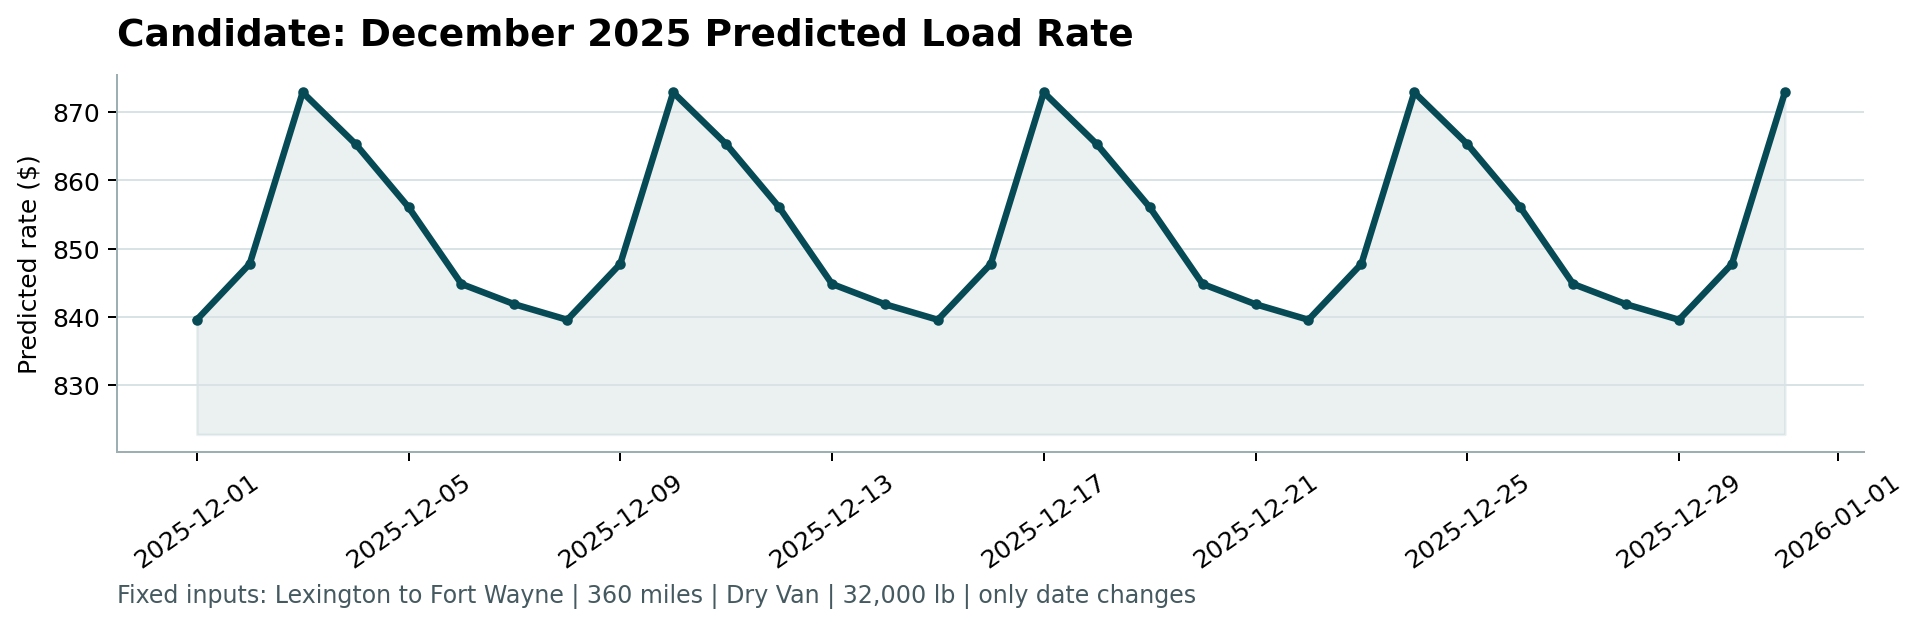

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import sys
import subprocess
from google.colab import files
from IPython.display import Image, display

uploaded = files.upload()

assert "score.py" in uploaded, "Please upload the original score.py."

score_path = PROJECT_DIR / "score.py"
score_path.write_bytes(uploaded["score.py"])

SCORER_DIR = PROJECT_DIR / "scorer_results"

result = subprocess.run(
    [
        sys.executable,
        str(score_path),
        "--predictions", str(submission_path),
        "--december-predictions", str(december_path),
        "--output-dir", str(SCORER_DIR),
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Scorer failed. Share the output above.")

chart_path = SCORER_DIR / "candidate_december.png"
assert chart_path.is_file()

display(Image(filename=str(chart_path)))

# Download the main required prediction file.
files.download(str(submission_path))

In [29]:
print("Final tree count:", final_tree_count)

Final tree count: 425
